In [51]:
import pandas as pd
import pyam
import yaml
import warnings
warnings.filterwarnings('ignore')

In [52]:
df1 = pd.read_csv('mm_comparison_june12/MESSAGE_CANADA_provincial_netzero_v1.csv')
df2 = pd.read_csv('mm_comparison_june12/MESSAGE_CANADA_provincial_netzero_lowcost_v1.csv')
df3 = pd.read_csv('mm_comparison_june12/MESSAGE_CANADA_provincial_netzero_highcost_v1.csv')
df4 = pd.read_csv('mm_comparison_june12/MESSAGE_CANADA_provincial_baseline_v1.csv')

In [53]:
df = pd.concat([df1,df2,df3,df4])

In [54]:
df_pyam = pyam.IamDataFrame(df)

In [55]:
df_pyam.scenario

['Net Zero', 'Net Zero High Cost', 'Net Zero Low Cost', 'Reference']

In [57]:
with open('output_mapping.yaml', 'r') as f:
    category_mappings = yaml.safe_load(f)


In [58]:
for key, components in category_mappings.items():
    print(key)
    # Aggregates variables as per standard reporting
    df_pyam.aggregate(key, components=components, append=True)

Primary Energy|Biomass
Primary Energy|Hydrogen Production
Primary Energy|LNG
Primary Energy|Coal|Production
Primary Energy|Coal|Export
Primary Energy|Gas|Production


pyam.utils - WARNING: Formatted data is empty!


Primary Energy|Gas|Export
Primary Energy|Oil|Production
Primary Energy|Oil|Export
Primary Energy|renewable|hydro


pyam.utils - WARNING: Formatted data is empty!


Primary Energy|renewable|biomass
Primary Energy|renewable|solar


pyam.utils - WARNING: Formatted data is empty!


Primary Energy|renewable|wind
Primary Energy|Liquid Hydrogen
Primary Energy|Methanol
Primary Energy|Ethanol


pyam.utils - WARNING: Formatted data is empty!


Useful Energy|non-Commercial biomass
Useful Energy|residential/commercial thermal
Useful Energy|residential/commercial specific
Useful Energy|Industrial thermal
Useful Energy|Industrial specific
Useful Energy|Industrial feedstock
Useful Energy|Transport
Emissions|CO2_industry
Emissions|CO2_res_com
Emissions|CO2_transformation
Emissions|Co2_transport
Emissions|CO2
Emissions|CO2|Cement
Emissions|CO2|Coal
Emissions|CO2|Fuel oil
Emissions|CO2|Gas
Emissions|CO2|Lignite
Emissions|CO2|Light Oil
Emissions|CO2|Meth_ccs
Emissions|CO2|Oil
Emissions|CO2|Oil trade
Emissions|CO2|Gas trade
Emissions|TCE
Total Costs|Coal
Total Costs|biomass
Total Costs|Electricity
Total Costs|oil
Total Costs|Gas
Total Costs|Geothermal
Total Costs|Solar
Total Costs|Wind
Total Costs|Hydro
Total Costs|Nuclear
Secondary Energy|LNG
Secondary Energy|Coal
Secondary Energy|Oil
Secondary Energy|District Heat
Secondary Energy|Electricity|Biomass
Secondary Energy|Electricity|Biomass w/ CCS
Secondary Energy|Electricity|Biomass w/

In [59]:
df_pyam.to_csv('mm_comparison_june12/combined_outputs.csv')

In [36]:
df_pyam.filter(variable = 'Emission|TCE*').variable

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)
pyam.core - WARNING: Filtered IamDataFrame is empty!


[]

In [41]:
df_pyam.filter(region = 'Canada', variable = 'Emissions|TCE*').to_csv('TCE_emis.csv')

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)


In [42]:
df_pyam.filter(region = 'Canada', variable = 'Useful Energy*').to_csv('Useful_energy.csv')

/Users/muhammadawais/miniconda3/envs/message3.8/lib/python3.10/site-packages/pyam/core.py:2691: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  index = pd.unique(index)


In [ ]:
df_pyam.filter(region = 'Canada', variable = 'Emissions|TCE*').to_csv('TCE_emis.csv')

In [8]:
# Save the aggregated data back to a CSV file
if aggregated_df:
    aggregated_df.to_csv('aggregated_output.csv')
else:
    print("No data to save.")

No data to save.


In [ ]:
df.to_excel(DATA / 'historical_activity.xlsx', index=False)

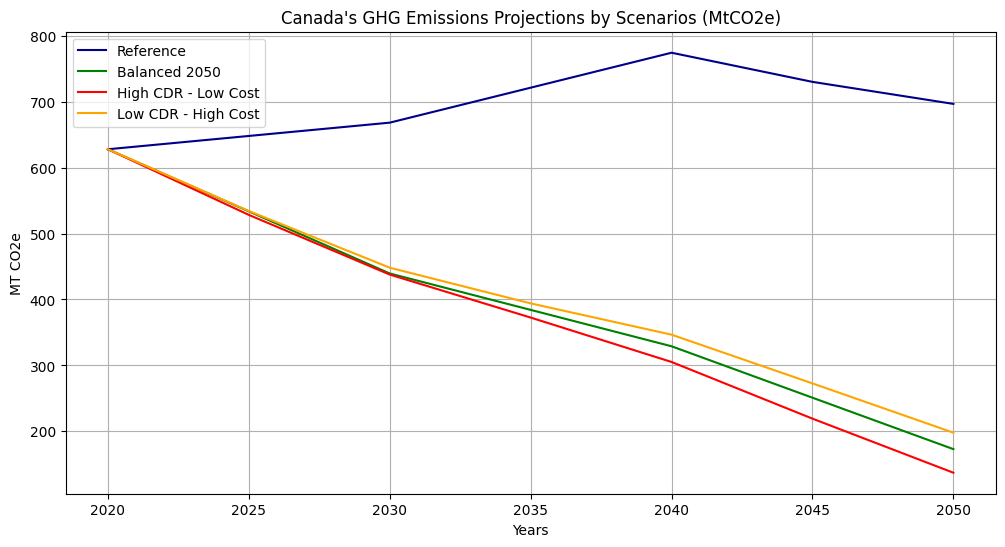

In [50]:
import matplotlib.pyplot as plt

# Data from the image provided
years = [2020, 2025, 2030, 2035, 2040, 2045, 2050]
reference = [627.8082303, 647.9741152, 668.14, 721.17, 774.2, 730, 696.6]
net_zero_pathway = [627.8082303, 533.6041152, 439.4, 384.2, 329, 251, 173]
high_cdr_low_cost = [627.8082303, 528.268074, 437.73, 372.55, 305.2, 219.24, 137.24]
low_cdr_high_cost = [627.8082303, 534.1377193, 448.188, 394.07, 346.6, 272.7, 198]

# Create the line plot
plt.figure(figsize=(12, 6))
plt.plot(years, reference, label='Reference', color='darkblue')
plt.plot(years, net_zero_pathway, label='Balanced 2050', color='green')
plt.plot(years, high_cdr_low_cost, label='High CDR - Low Cost', color='red')
plt.plot(years, low_cdr_high_cost, label='Low CDR - High Cost', color='orange')

# Add titles and labels
plt.title("Canada's GHG Emissions Projections by Scenarios (MtCO2e)")
plt.xlabel('Years')
plt.ylabel('MT CO2e')

# Add a legend
plt.legend()

# Display the plot
plt.grid(True)
plt.show()


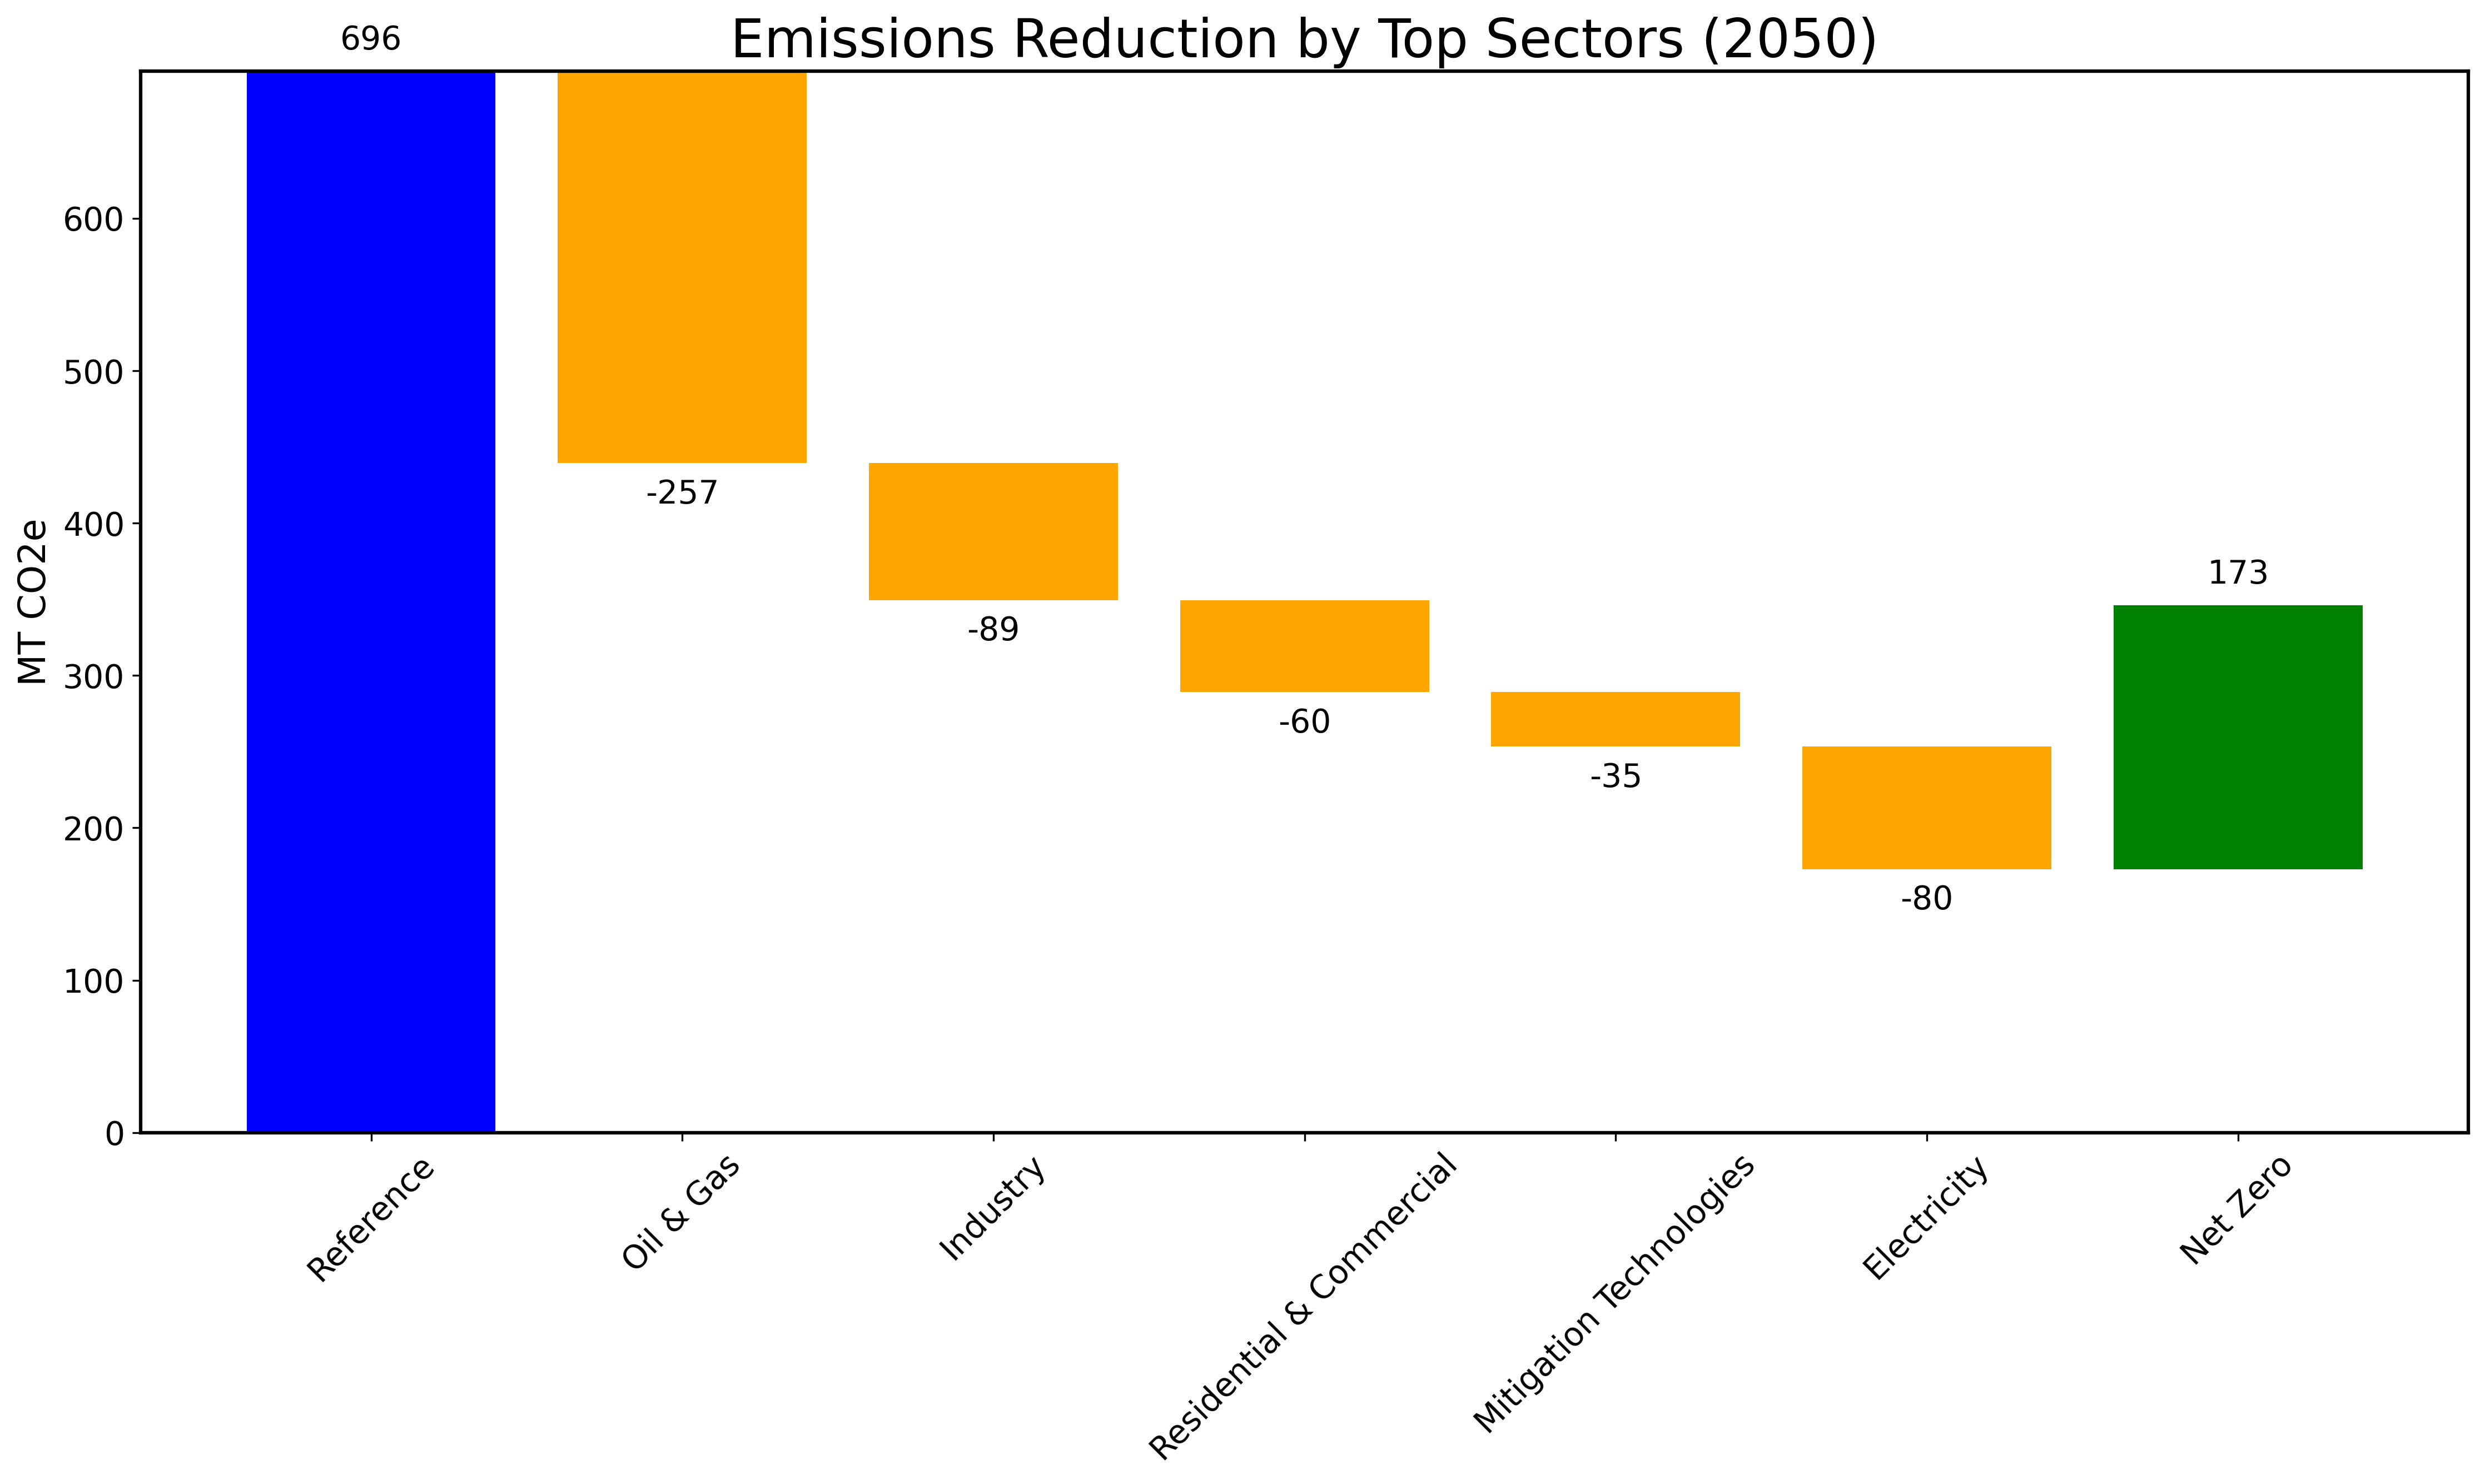

In [69]:
import matplotlib.pyplot as plt
import numpy as np

# Data from the image provided
categories = ['Reference', 'Oil & Gas', 'Industry', 'Residential & Commercial', 'Mitigation Technologies', 'Electricity', 'Net Zero']
values = [696.6, -257.3225, -89.8, -60.3725, -35.75, -80.355, 173]

# Compute the cumulative values for the waterfall plot
cumulative_values = np.cumsum(values)
cumulative_values = np.insert(cumulative_values, 0, 0)  # Start from zero
cumulative_values = cumulative_values[:-1]  # Exclude the last cumulative value

# Define colors for each category
colors = ['blue', 'orange', 'orange', 'orange', 'orange', 'orange', 'green']

# Create the waterfall plot
fig, ax = plt.subplots(figsize=(15, 9), dpi=300)  # Higher resolution and larger size

for i in range(len(values)):
    bar = ax.bar(categories[i], values[i], bottom=cumulative_values[i], color=colors[i])
    height = bar[0].get_height()
    if values[i] < 0:
        ax.text(categories[i], cumulative_values[i] + height - 10, f'{int(values[i])}', ha='center', va='top', fontsize=14, color='black')
    else:
        ax.text(categories[i], cumulative_values[i] + height + 10, f'{int(values[i])}', ha='center', va='bottom', fontsize=14, color='black')

# Add titles and labels with increased fontsize
plt.title("Emissions Reduction by Top Sectors (2050)", fontsize=23)
plt.ylabel('MT CO2e', fontsize=16)

# Increase the size of tick labels
plt.xticks(rotation=45, fontsize=14)
plt.yticks(fontsize=14)

# Add a box around the plot
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.5)

# Remove internal plot lines
ax.grid(False)

# Display the plot
plt.tight_layout()
plt.show()


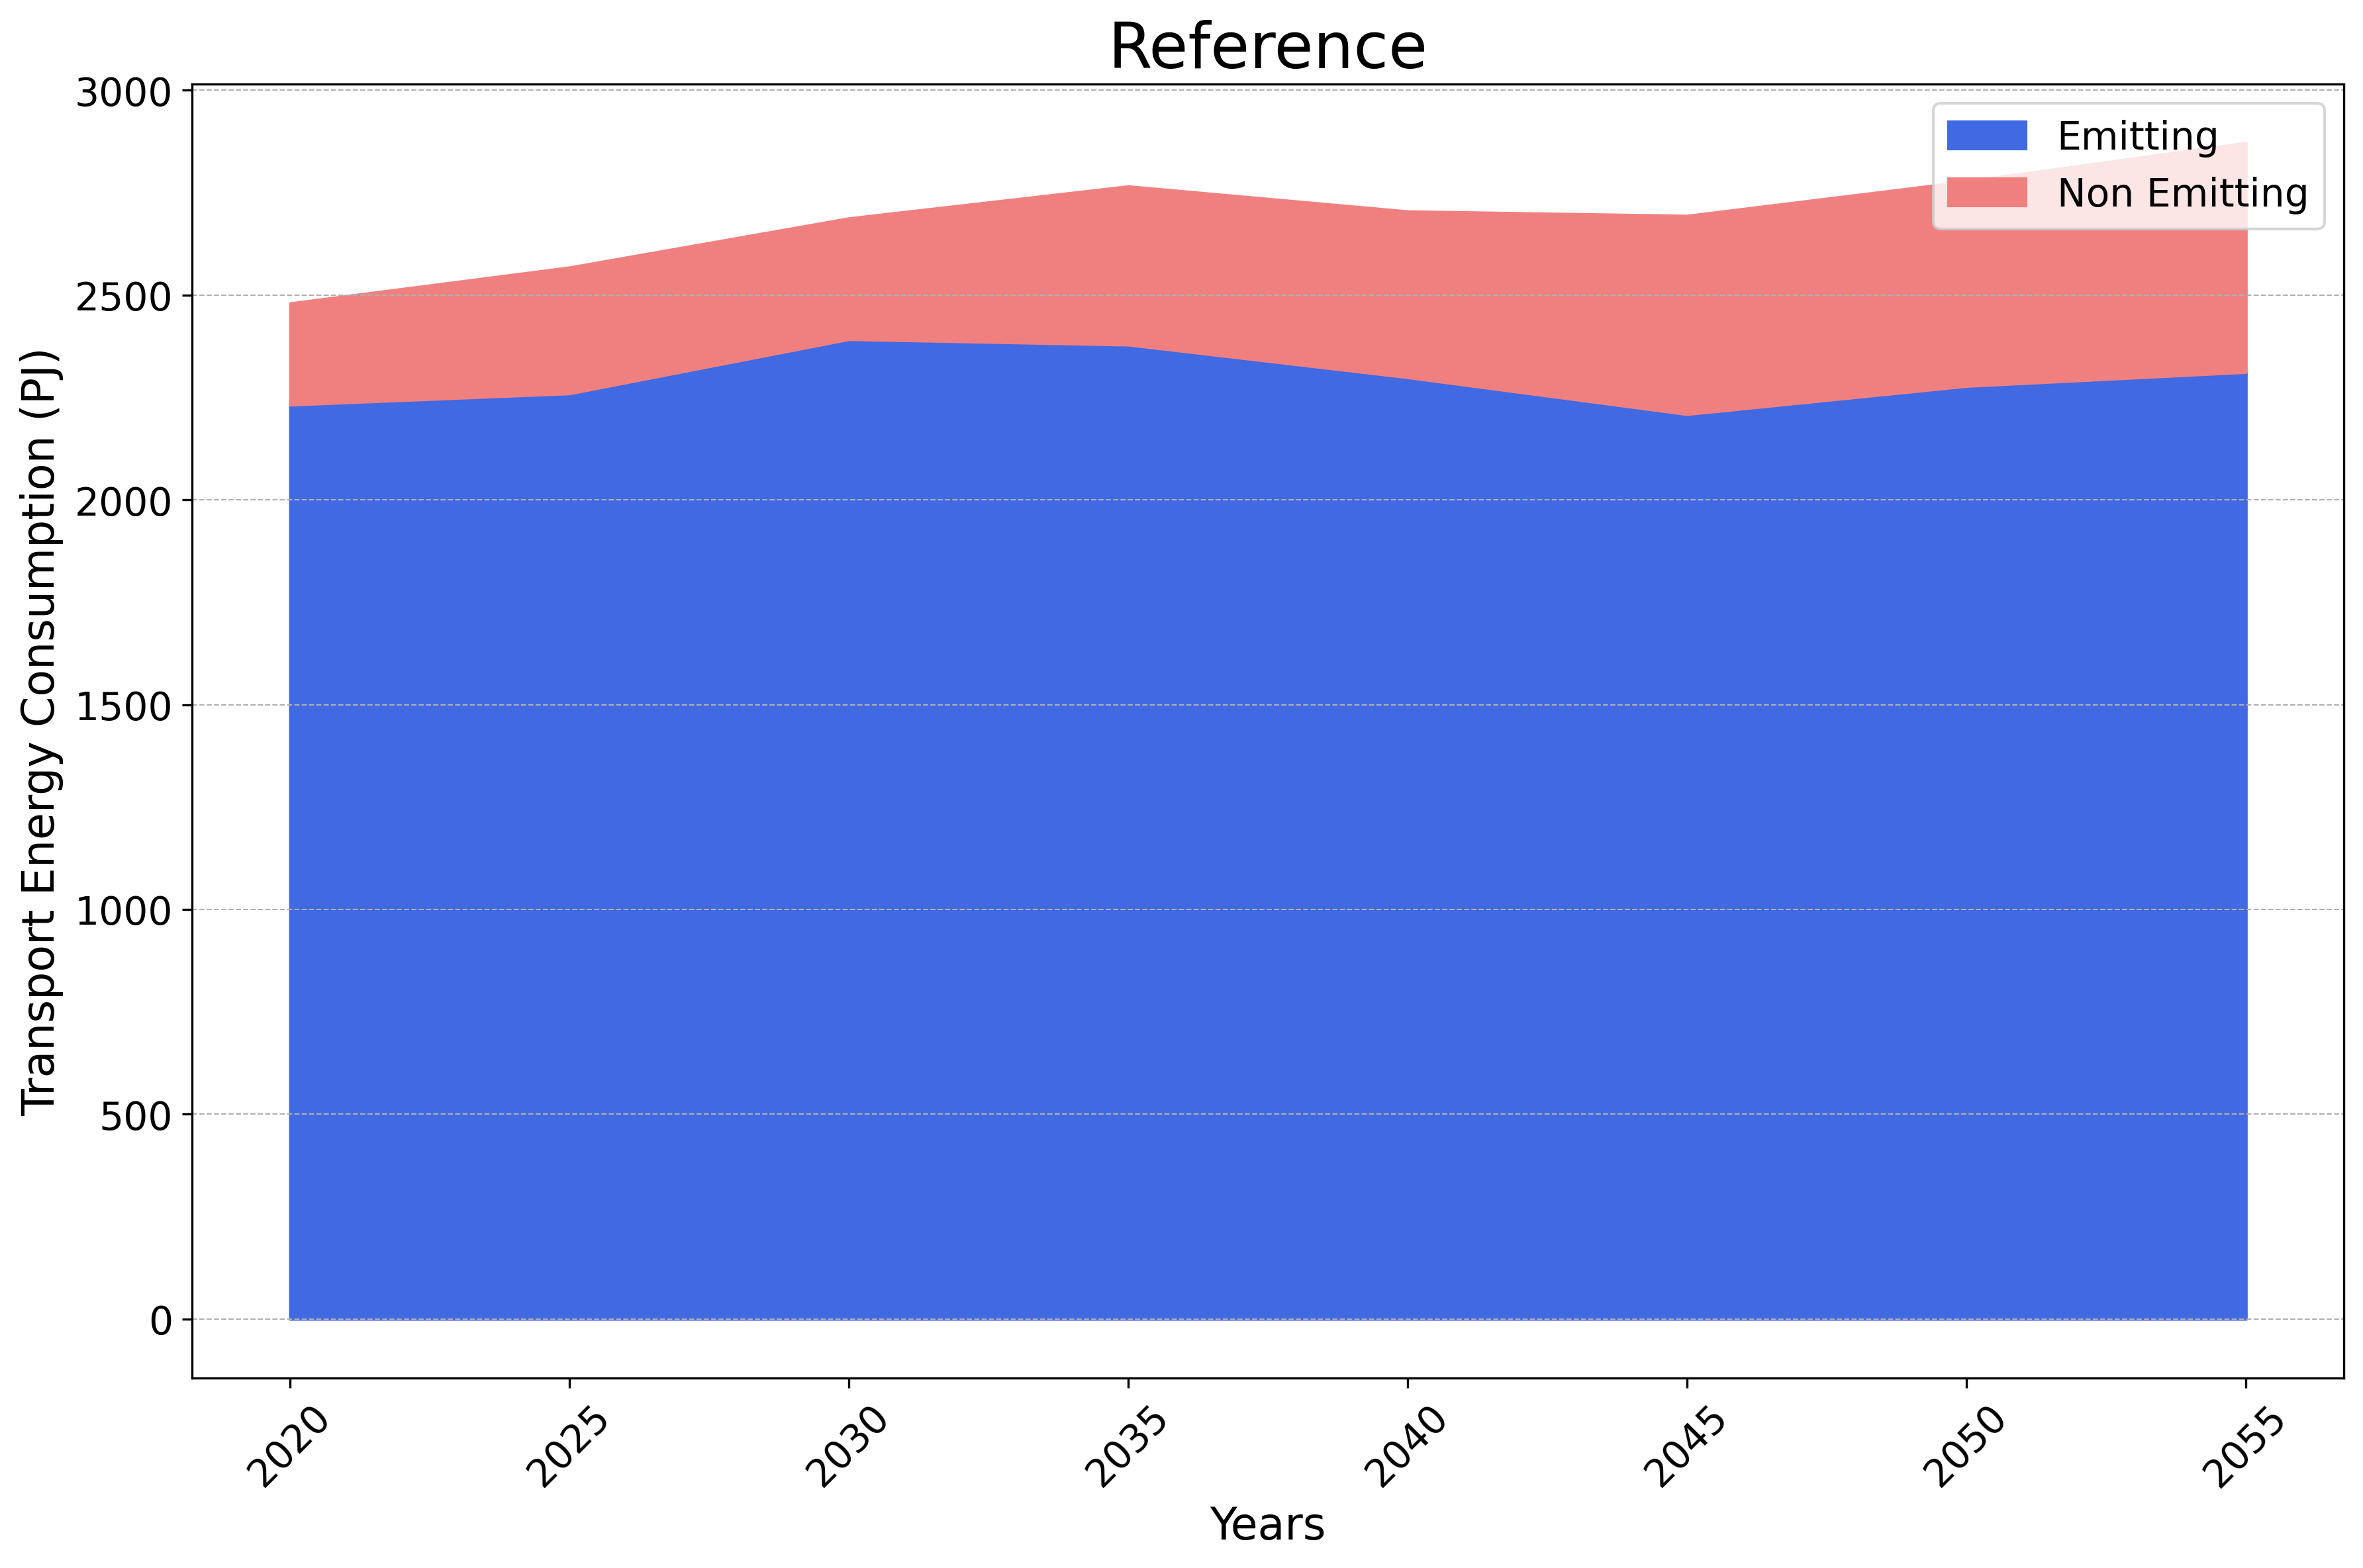

In [74]:
import pandas as pd
import matplotlib.pyplot as plt

# Updated data from the provided table
data = {
    'Transportation Sector': ['Emitting', 'Non Emitting', 'Emitting', 'Non Emitting'],
    'Scenario': ['Reference', 'Reference', 'Net Zero', 'Net Zero'],
    2020: [2231.803494, 247.978166, 2231.803494, 247.978166],
    2025: [2259.316928, 308.088672, 2236.723759, 305.0077853],
    2030: [2391.7148, 295.6052, 1929.585, 643.195],
    2035: [2378.2698, 387.1602, 1724.9616, 670.8184],
    2040: [2298.655, 405.645, 1403.7381, 897.4719],
    2045: [2208.7028, 484.8372, 990.4905, 1210.5995],
    2050: [2277.4188, 499.9212, 633.1299, 1477.3031],
    2055: [2311.4287, 559.9113, 508.6825639, 1526.047692]
}

df = pd.DataFrame(data)

# Filter data for the Reference scenario
df_reference = df[df['Scenario'] == 'Reference']

# Plotting
fig, ax = plt.subplots(figsize=(12, 8), dpi=300)

years = [2020, 2025, 2030, 2035, 2040, 2045, 2050, 2055]
emitting = df_reference[df_reference['Transportation Sector'] == 'Emitting'].iloc[:, 2:].values.flatten()
non_emitting = df_reference[df_reference['Transportation Sector'] == 'Non Emitting'].iloc[:, 2:].values.flatten()

ax.fill_between(years, emitting, color='royalblue', label='Emitting')
ax.fill_between(years, emitting + non_emitting, emitting, color='lightcoral', label='Non Emitting')

# Add titles and labels with increased fontsize
plt.title("Reference", fontsize=23)
plt.xlabel('Years', fontsize=16)
plt.ylabel('Transport Energy Consumption (PJ)', fontsize=16)

# Increase the size of tick labels
plt.xticks(rotation=45, fontsize=14)
plt.yticks(fontsize=14)

# Add a legend
plt.legend(fontsize=14)

# Add a grid
plt.grid(False, axis='y', linestyle='--', linewidth=0.5)

# Display the plot
plt.tight_layout()
plt.show()


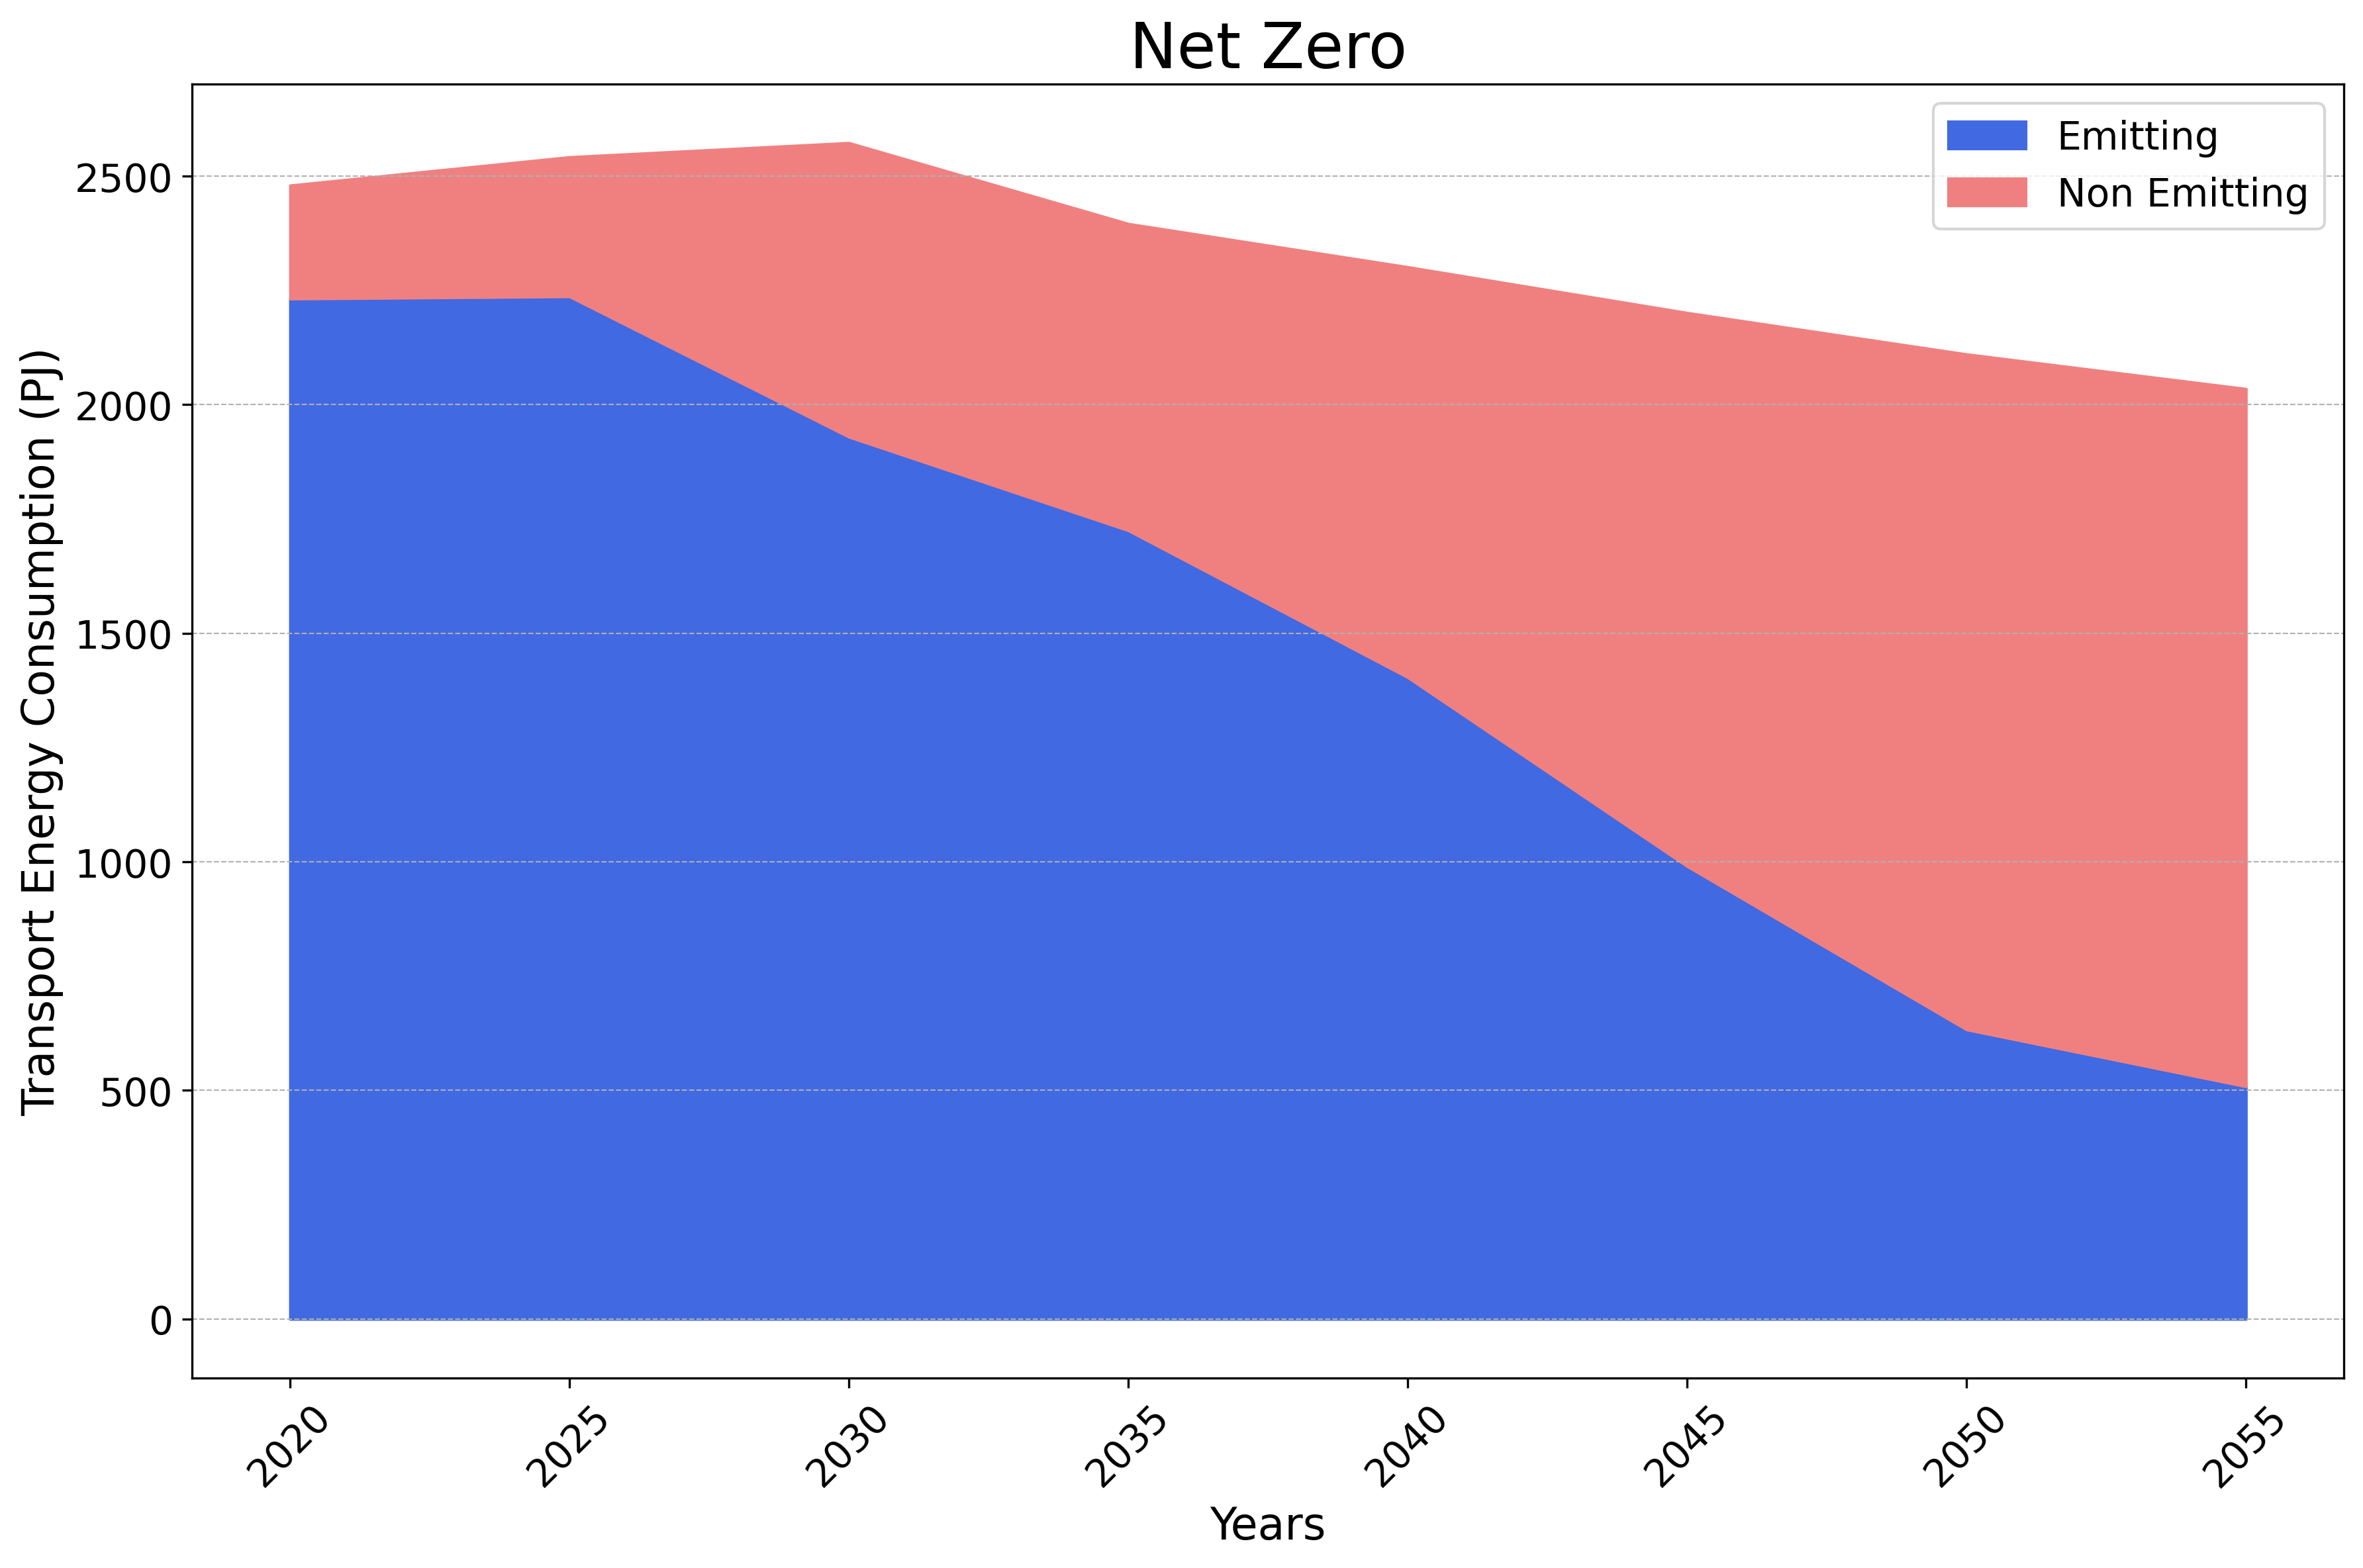

In [75]:
import pandas as pd
import matplotlib.pyplot as plt

# Updated data from the provided table
data = {
    'Transportation Sector': ['Emitting', 'Non Emitting', 'Emitting', 'Non Emitting'],
    'Scenario': ['Reference', 'Reference', 'Net Zero', 'Net Zero'],
    2020: [2231.803494, 247.978166, 2231.803494, 247.978166],
    2025: [2259.316928, 308.088672, 2236.723759, 305.0077853],
    2030: [2391.7148, 295.6052, 1929.585, 643.195],
    2035: [2378.2698, 387.1602, 1724.9616, 670.8184],
    2040: [2298.655, 405.645, 1403.7381, 897.4719],
    2045: [2208.7028, 484.8372, 990.4905, 1210.5995],
    2050: [2277.4188, 499.9212, 633.1299, 1477.3031],
    2055: [2311.4287, 559.9113, 508.6825639, 1526.047692]
}

df = pd.DataFrame(data)

# Filter data for the Reference scenario
df_reference = df[df['Scenario'] == 'Net Zero']

# Plotting
fig, ax = plt.subplots(figsize=(12, 8), dpi=300)

years = [2020, 2025, 2030, 2035, 2040, 2045, 2050, 2055]
emitting = df_reference[df_reference['Transportation Sector'] == 'Emitting'].iloc[:, 2:].values.flatten()
non_emitting = df_reference[df_reference['Transportation Sector'] == 'Non Emitting'].iloc[:, 2:].values.flatten()

ax.fill_between(years, emitting, color='royalblue', label='Emitting')
ax.fill_between(years, emitting + non_emitting, emitting, color='lightcoral', label='Non Emitting')

# Add titles and labels with increased fontsize
plt.title("Net Zero", fontsize=23)
plt.xlabel('Years', fontsize=16)
plt.ylabel('Transport Energy Consumption (PJ)', fontsize=16)

# Increase the size of tick labels
plt.xticks(rotation=45, fontsize=14)
plt.yticks(fontsize=14)

# Add a legend
plt.legend(fontsize=14)

# Add a grid
plt.grid(False, axis='y', linestyle='--', linewidth=0.5)

# Display the plot
plt.tight_layout()
plt.show()


## Industrial Sectors

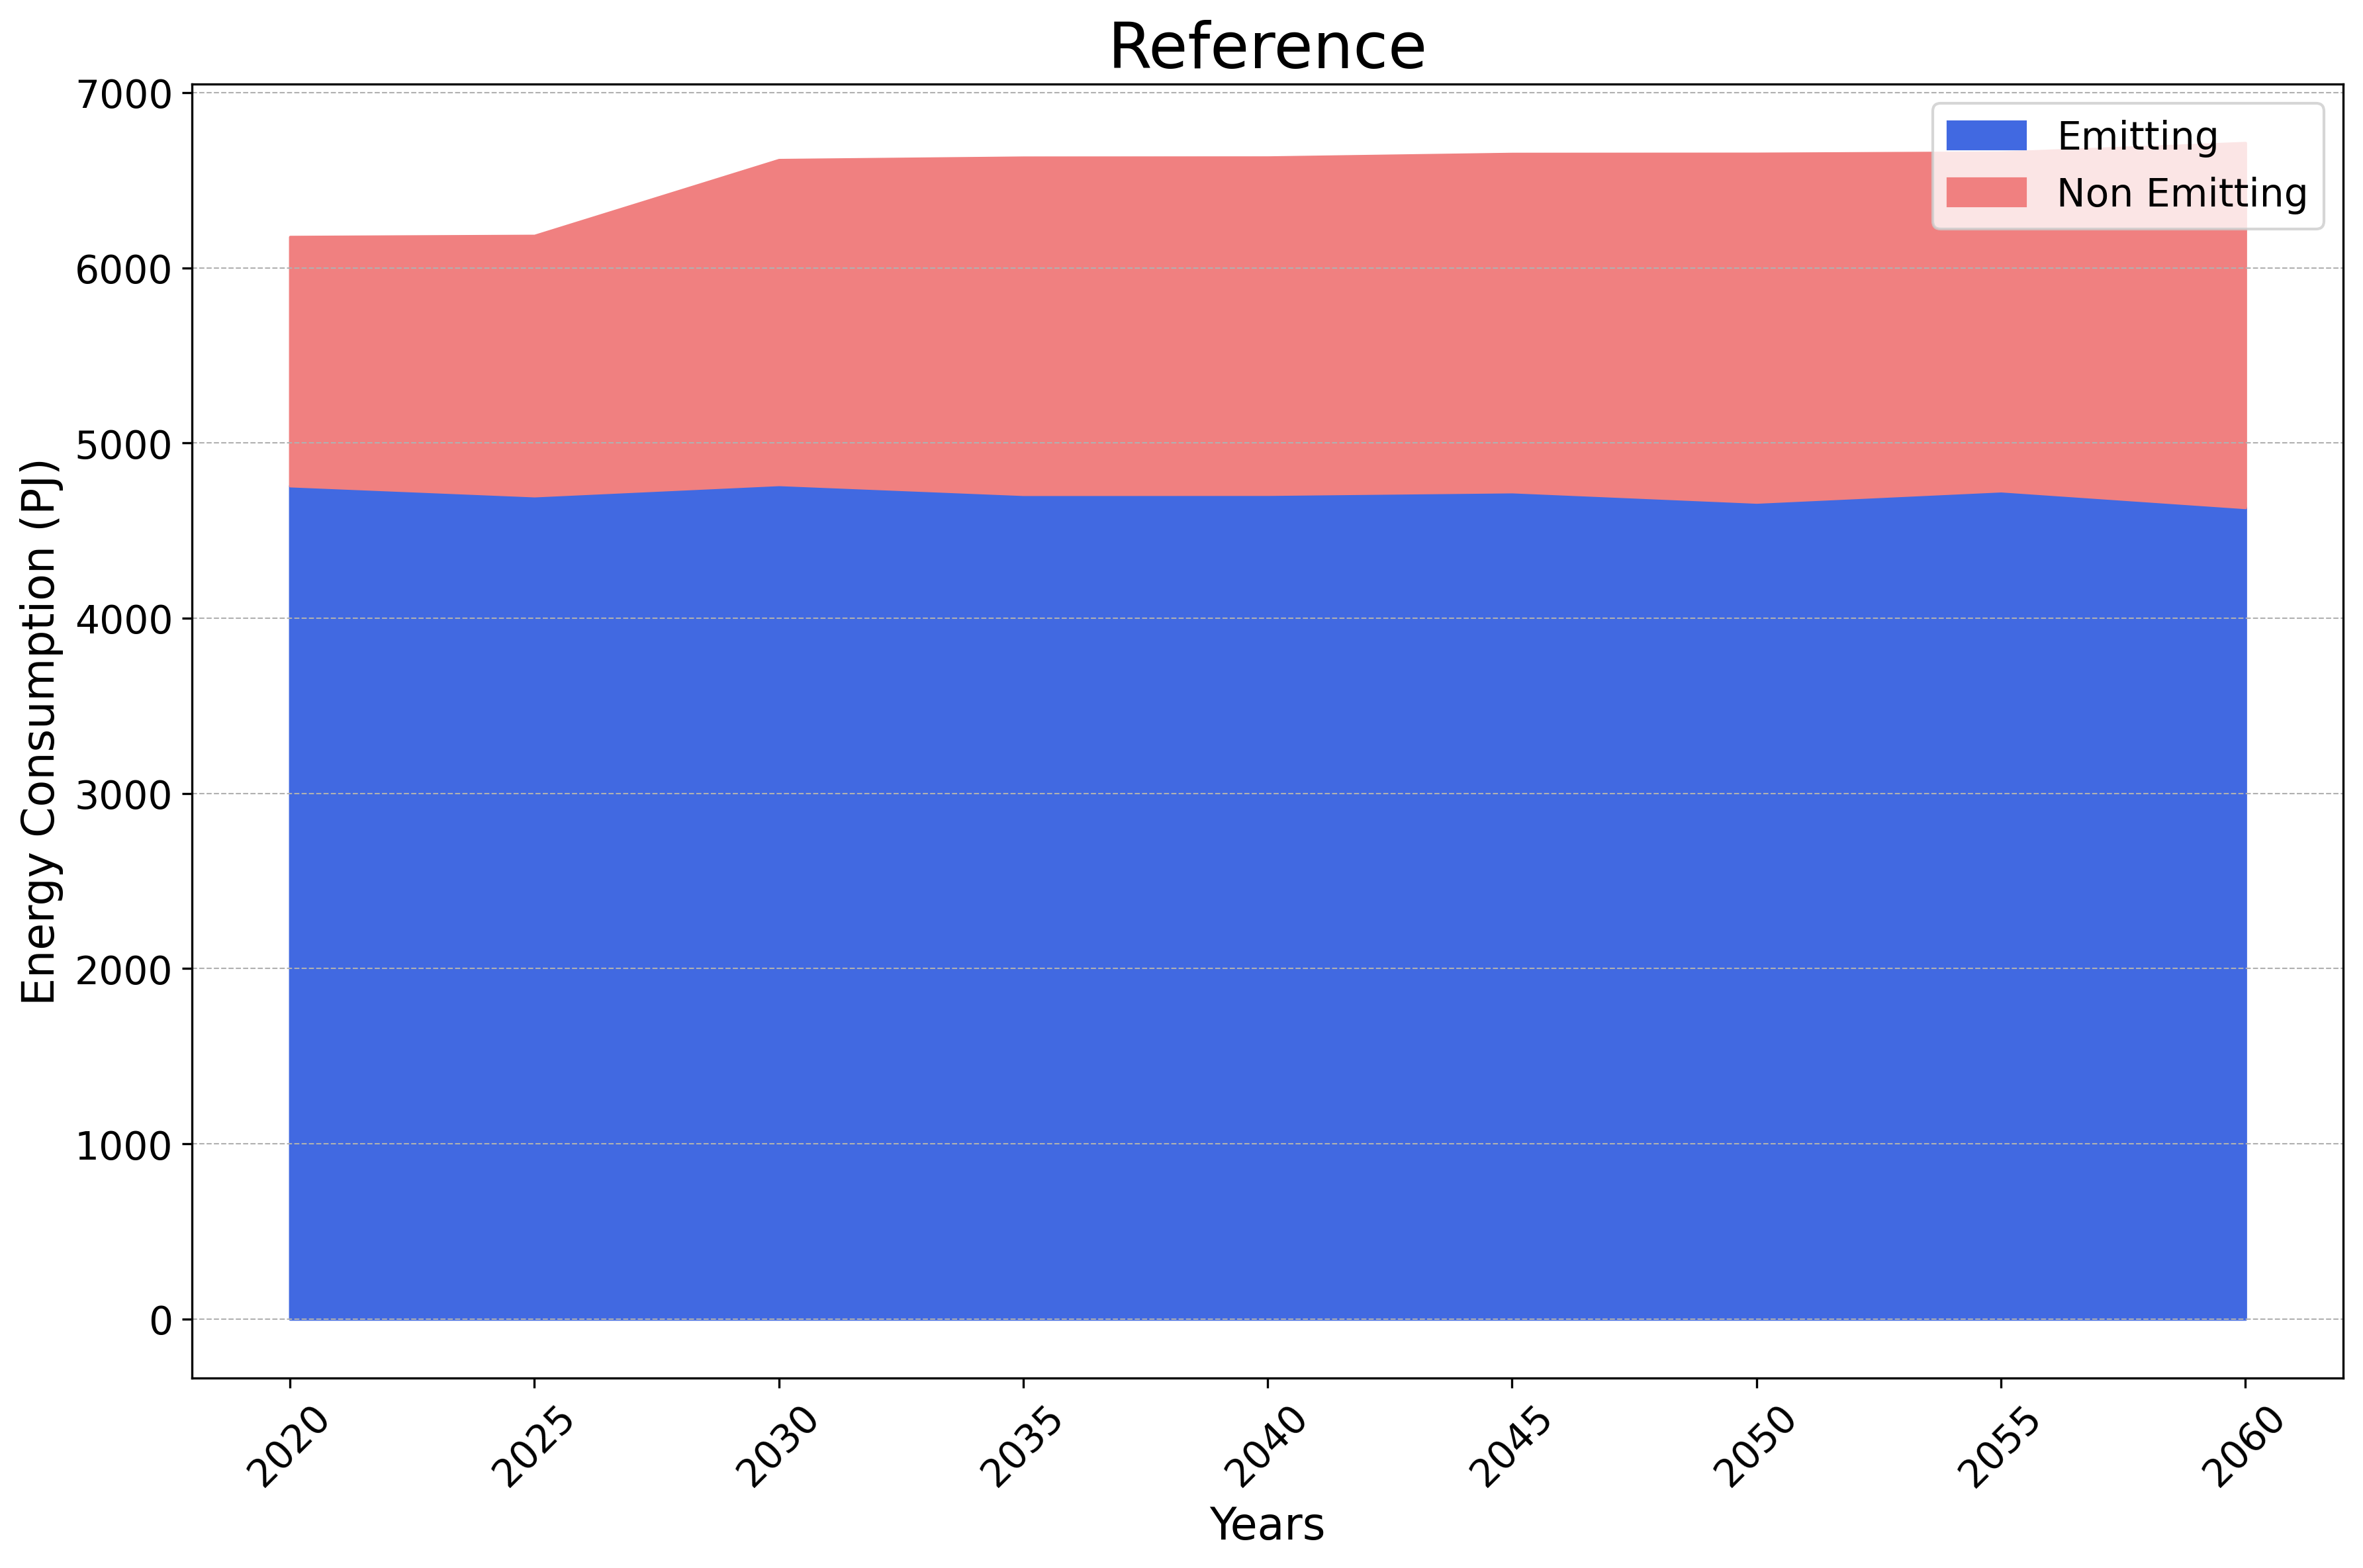

In [80]:
import pandas as pd
import matplotlib.pyplot as plt

# Updated data for the industrial sector
data = {
    'Industrial Sector': ['Emitting', 'Non Emitting', 'Emitting', 'Non Emitting'],
    'Scenario': ['Reference', 'Reference', 'Net Zero', 'Net Zero'],
    2020: [4755.8588, 1420.5812, 4755.8588, 1420.5812],
    2025: [4698.788494, 1483.827946, 5438.972, 741.678],
    2030: [4763.087705, 1852.311885, 4496.422875, 1498.807625],
    2035: [4706.79727, 1922.49466, 4273.4003, 1661.877895],
    2040: [4707.26795, 1922.686909, 4034.208589, 1728.946538],
    2045: [4721.860481, 1928.647239, 3350.698391, 2233.798927],
    2050: [4662.565352, 1988.740428, 2819.724386, 2602.82251],
    2055: [4727.149531, 1930.807555, 2134.504179, 3201.756269],
    2060: [4631.7285, 2080.9215, 1574.9922, 3674.9818]
}

df = pd.DataFrame(data)

# Filter data for the Reference scenario
df_reference = df[df['Scenario'] == 'Reference']

# Plotting
fig, ax = plt.subplots(figsize=(12, 8), dpi=300)

years = [2020, 2025, 2030, 2035, 2040, 2045, 2050, 2055, 2060]
emitting = df_reference[df_reference['Industrial Sector'] == 'Emitting'].iloc[:, 2:].values.flatten()
non_emitting = df_reference[df_reference['Industrial Sector'] == 'Non Emitting'].iloc[:, 2:].values.flatten()

ax.fill_between(years, emitting, color='royalblue', label='Emitting')
ax.fill_between(years, emitting + non_emitting, emitting, color='lightcoral', label='Non Emitting')

# Add titles and labels with increased fontsize
plt.title("Reference", fontsize=23)
plt.xlabel('Years', fontsize=16)
plt.ylabel('Energy Consumption (PJ)', fontsize=16)

# Increase the size of tick labels
plt.xticks(rotation=45, fontsize=14)
plt.yticks(fontsize=14)

# Add a legend
plt.legend(fontsize=14)

# Add a grid
plt.grid(False, axis='y', linestyle='--', linewidth=0.5)

# Display the plot
plt.tight_layout()
plt.show()


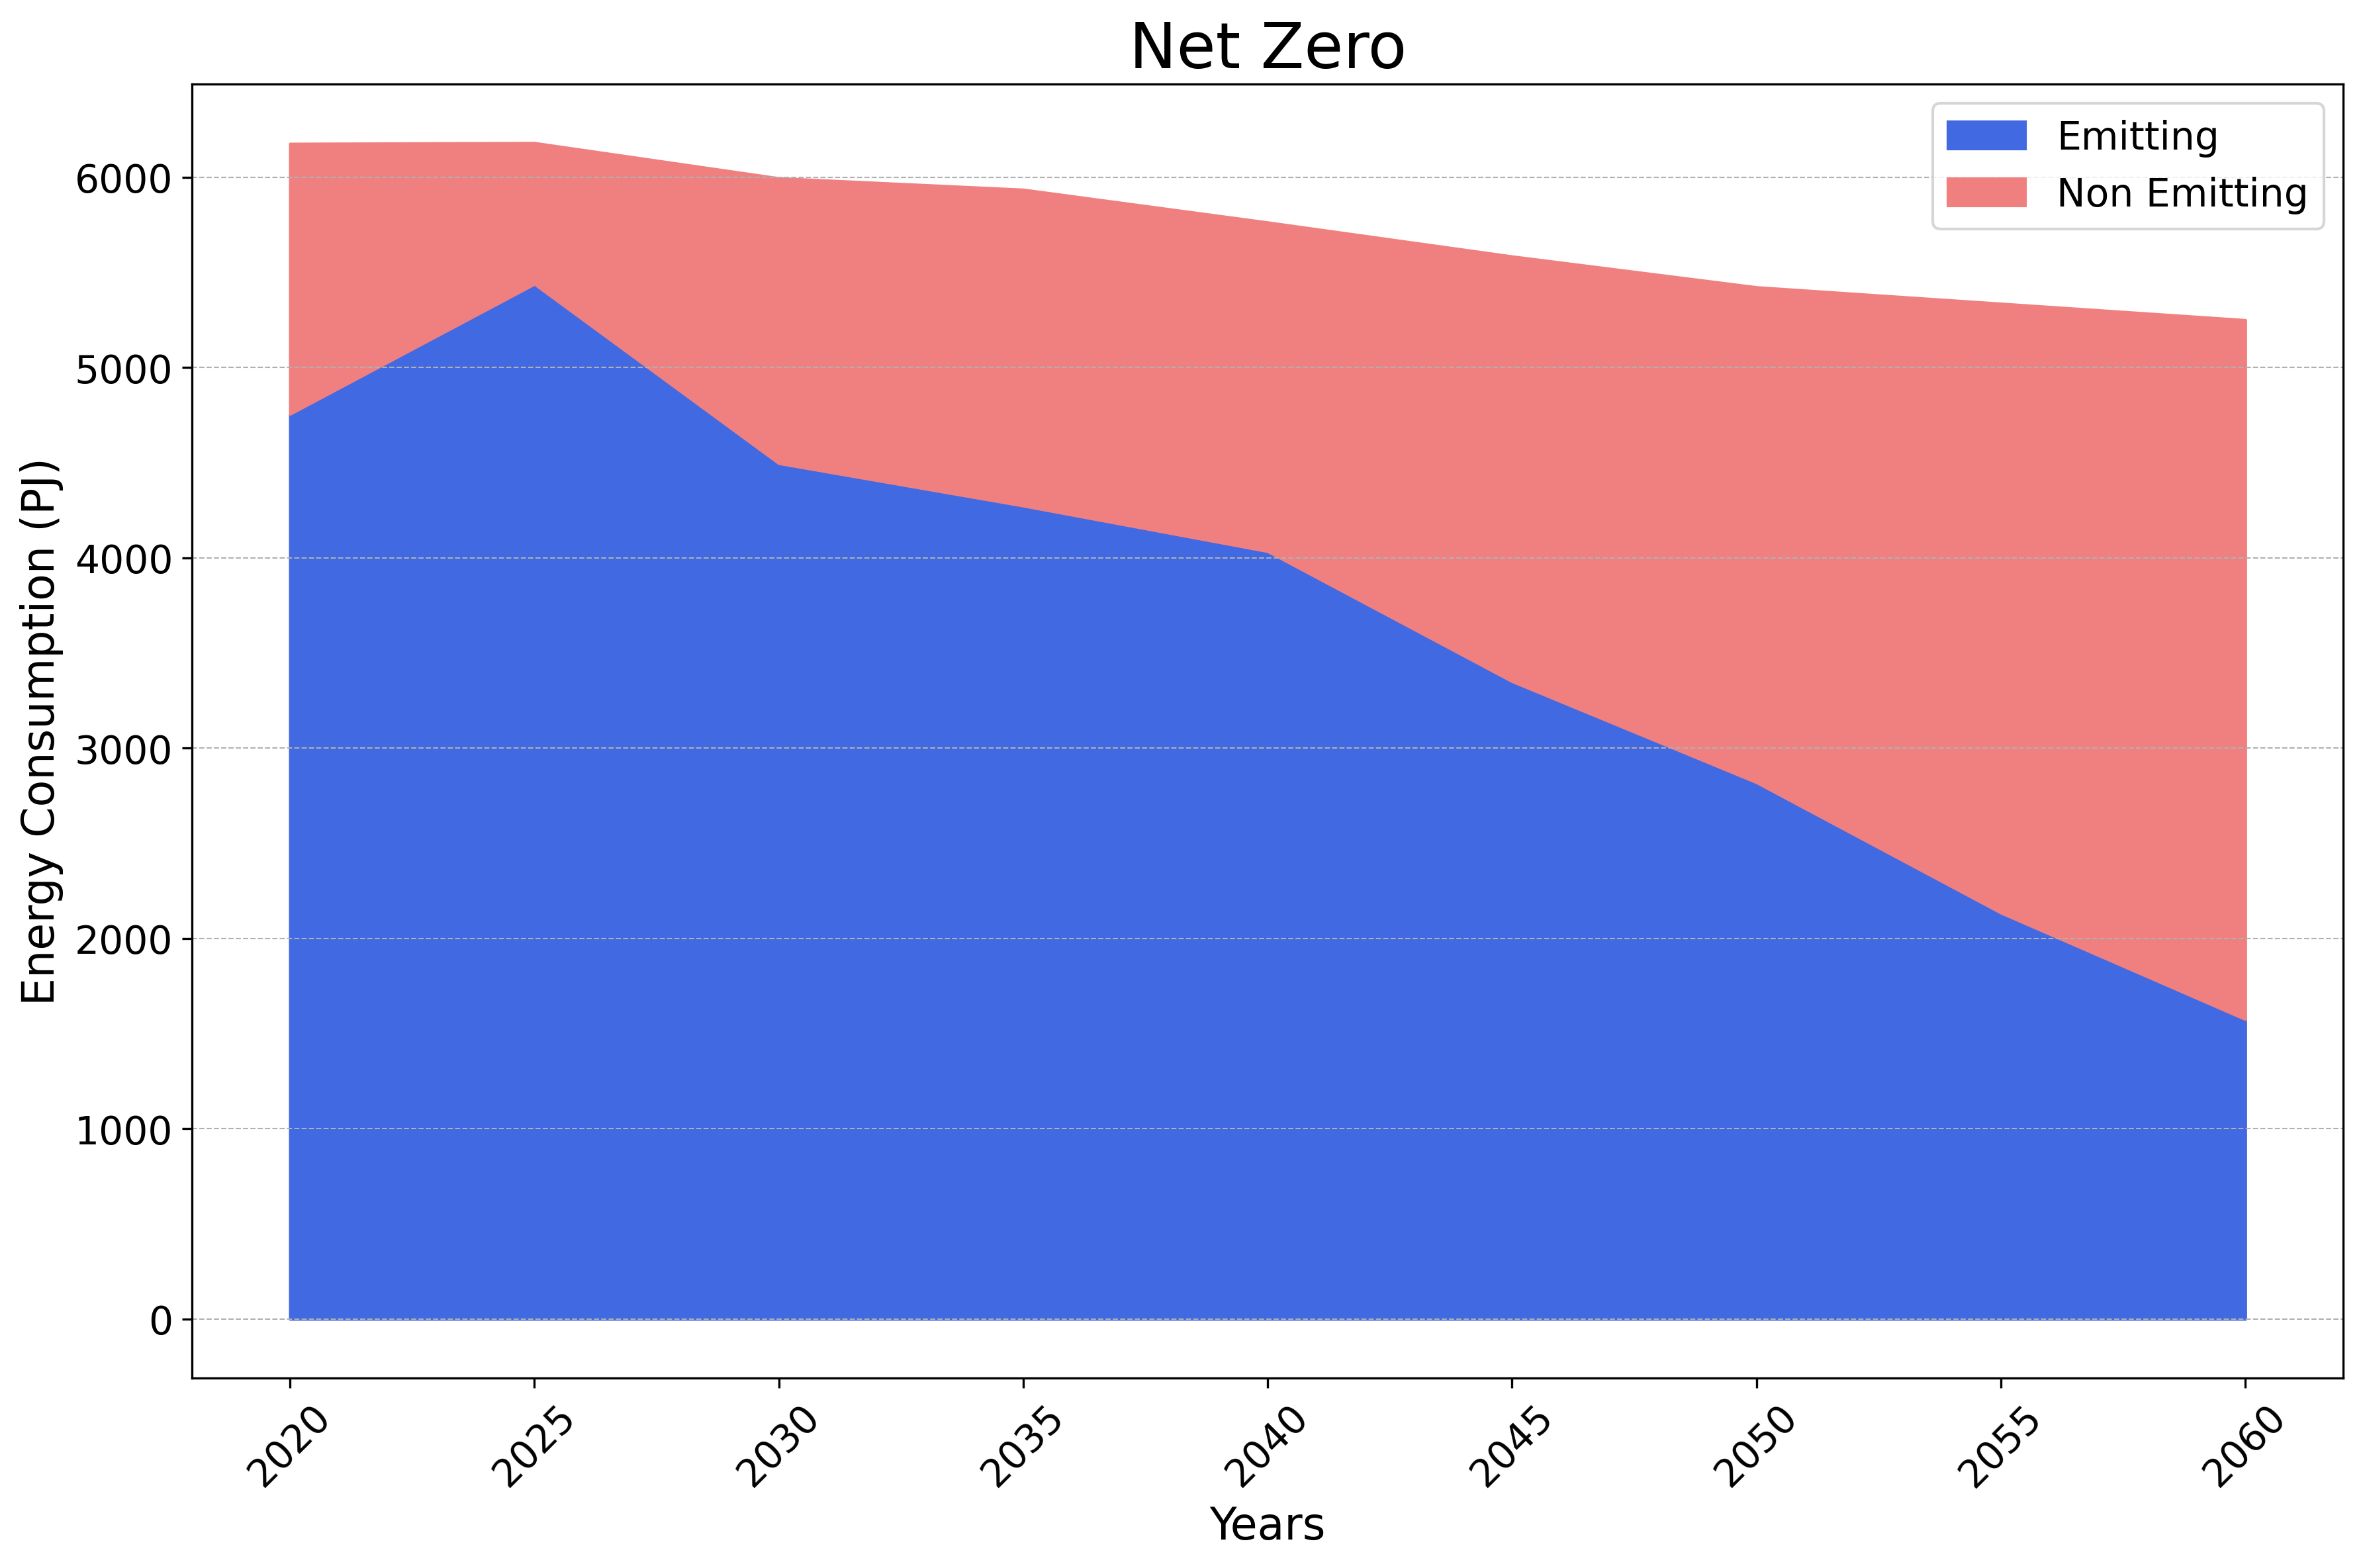

In [79]:
import pandas as pd
import matplotlib.pyplot as plt

# Updated data for the industrial sector
data = {
    'Industrial Sector': ['Emitting', 'Non Emitting', 'Emitting', 'Non Emitting'],
    'Scenario': ['Reference', 'Reference', 'Net Zero', 'Net Zero'],
    2020: [4755.8588, 1420.5812, 4755.8588, 1420.5812],
    2025: [4698.788494, 1483.827946, 5438.972, 741.678],
    2030: [4763.087705, 1852.311885, 4496.422875, 1498.807625],
    2035: [4706.79727, 1922.49466, 4273.4003, 1661.877895],
    2040: [4707.26795, 1922.686909, 4034.208589, 1728.946538],
    2045: [4721.860481, 1928.647239, 3350.698391, 2233.798927],
    2050: [4662.565352, 1988.740428, 2819.724386, 2602.82251],
    2055: [4727.149531, 1930.807555, 2134.504179, 3201.756269],
    2060: [4631.7285, 2080.9215, 1574.9922, 3674.9818]
}

df = pd.DataFrame(data)

# Filter data for the Reference scenario
df_reference = df[df['Scenario'] == 'Net Zero']

# Plotting
fig, ax = plt.subplots(figsize=(12, 8), dpi=300)

years = [2020, 2025, 2030, 2035, 2040, 2045, 2050, 2055, 2060]
emitting = df_reference[df_reference['Industrial Sector'] == 'Emitting'].iloc[:, 2:].values.flatten()
non_emitting = df_reference[df_reference['Industrial Sector'] == 'Non Emitting'].iloc[:, 2:].values.flatten()

ax.fill_between(years, emitting, color='royalblue', label='Emitting')
ax.fill_between(years, emitting + non_emitting, emitting, color='lightcoral', label='Non Emitting')

# Add titles and labels with increased fontsize
plt.title("Net Zero", fontsize=23)
plt.xlabel('Years', fontsize=16)
plt.ylabel('Energy Consumption (PJ)', fontsize=16)

# Increase the size of tick labels
plt.xticks(rotation=45, fontsize=14)
plt.yticks(fontsize=14)

# Add a legend
plt.legend(fontsize=14)

# Add a grid
plt.grid(False, axis='y', linestyle='--', linewidth=0.5)

# Display the plot
plt.tight_layout()
plt.show()


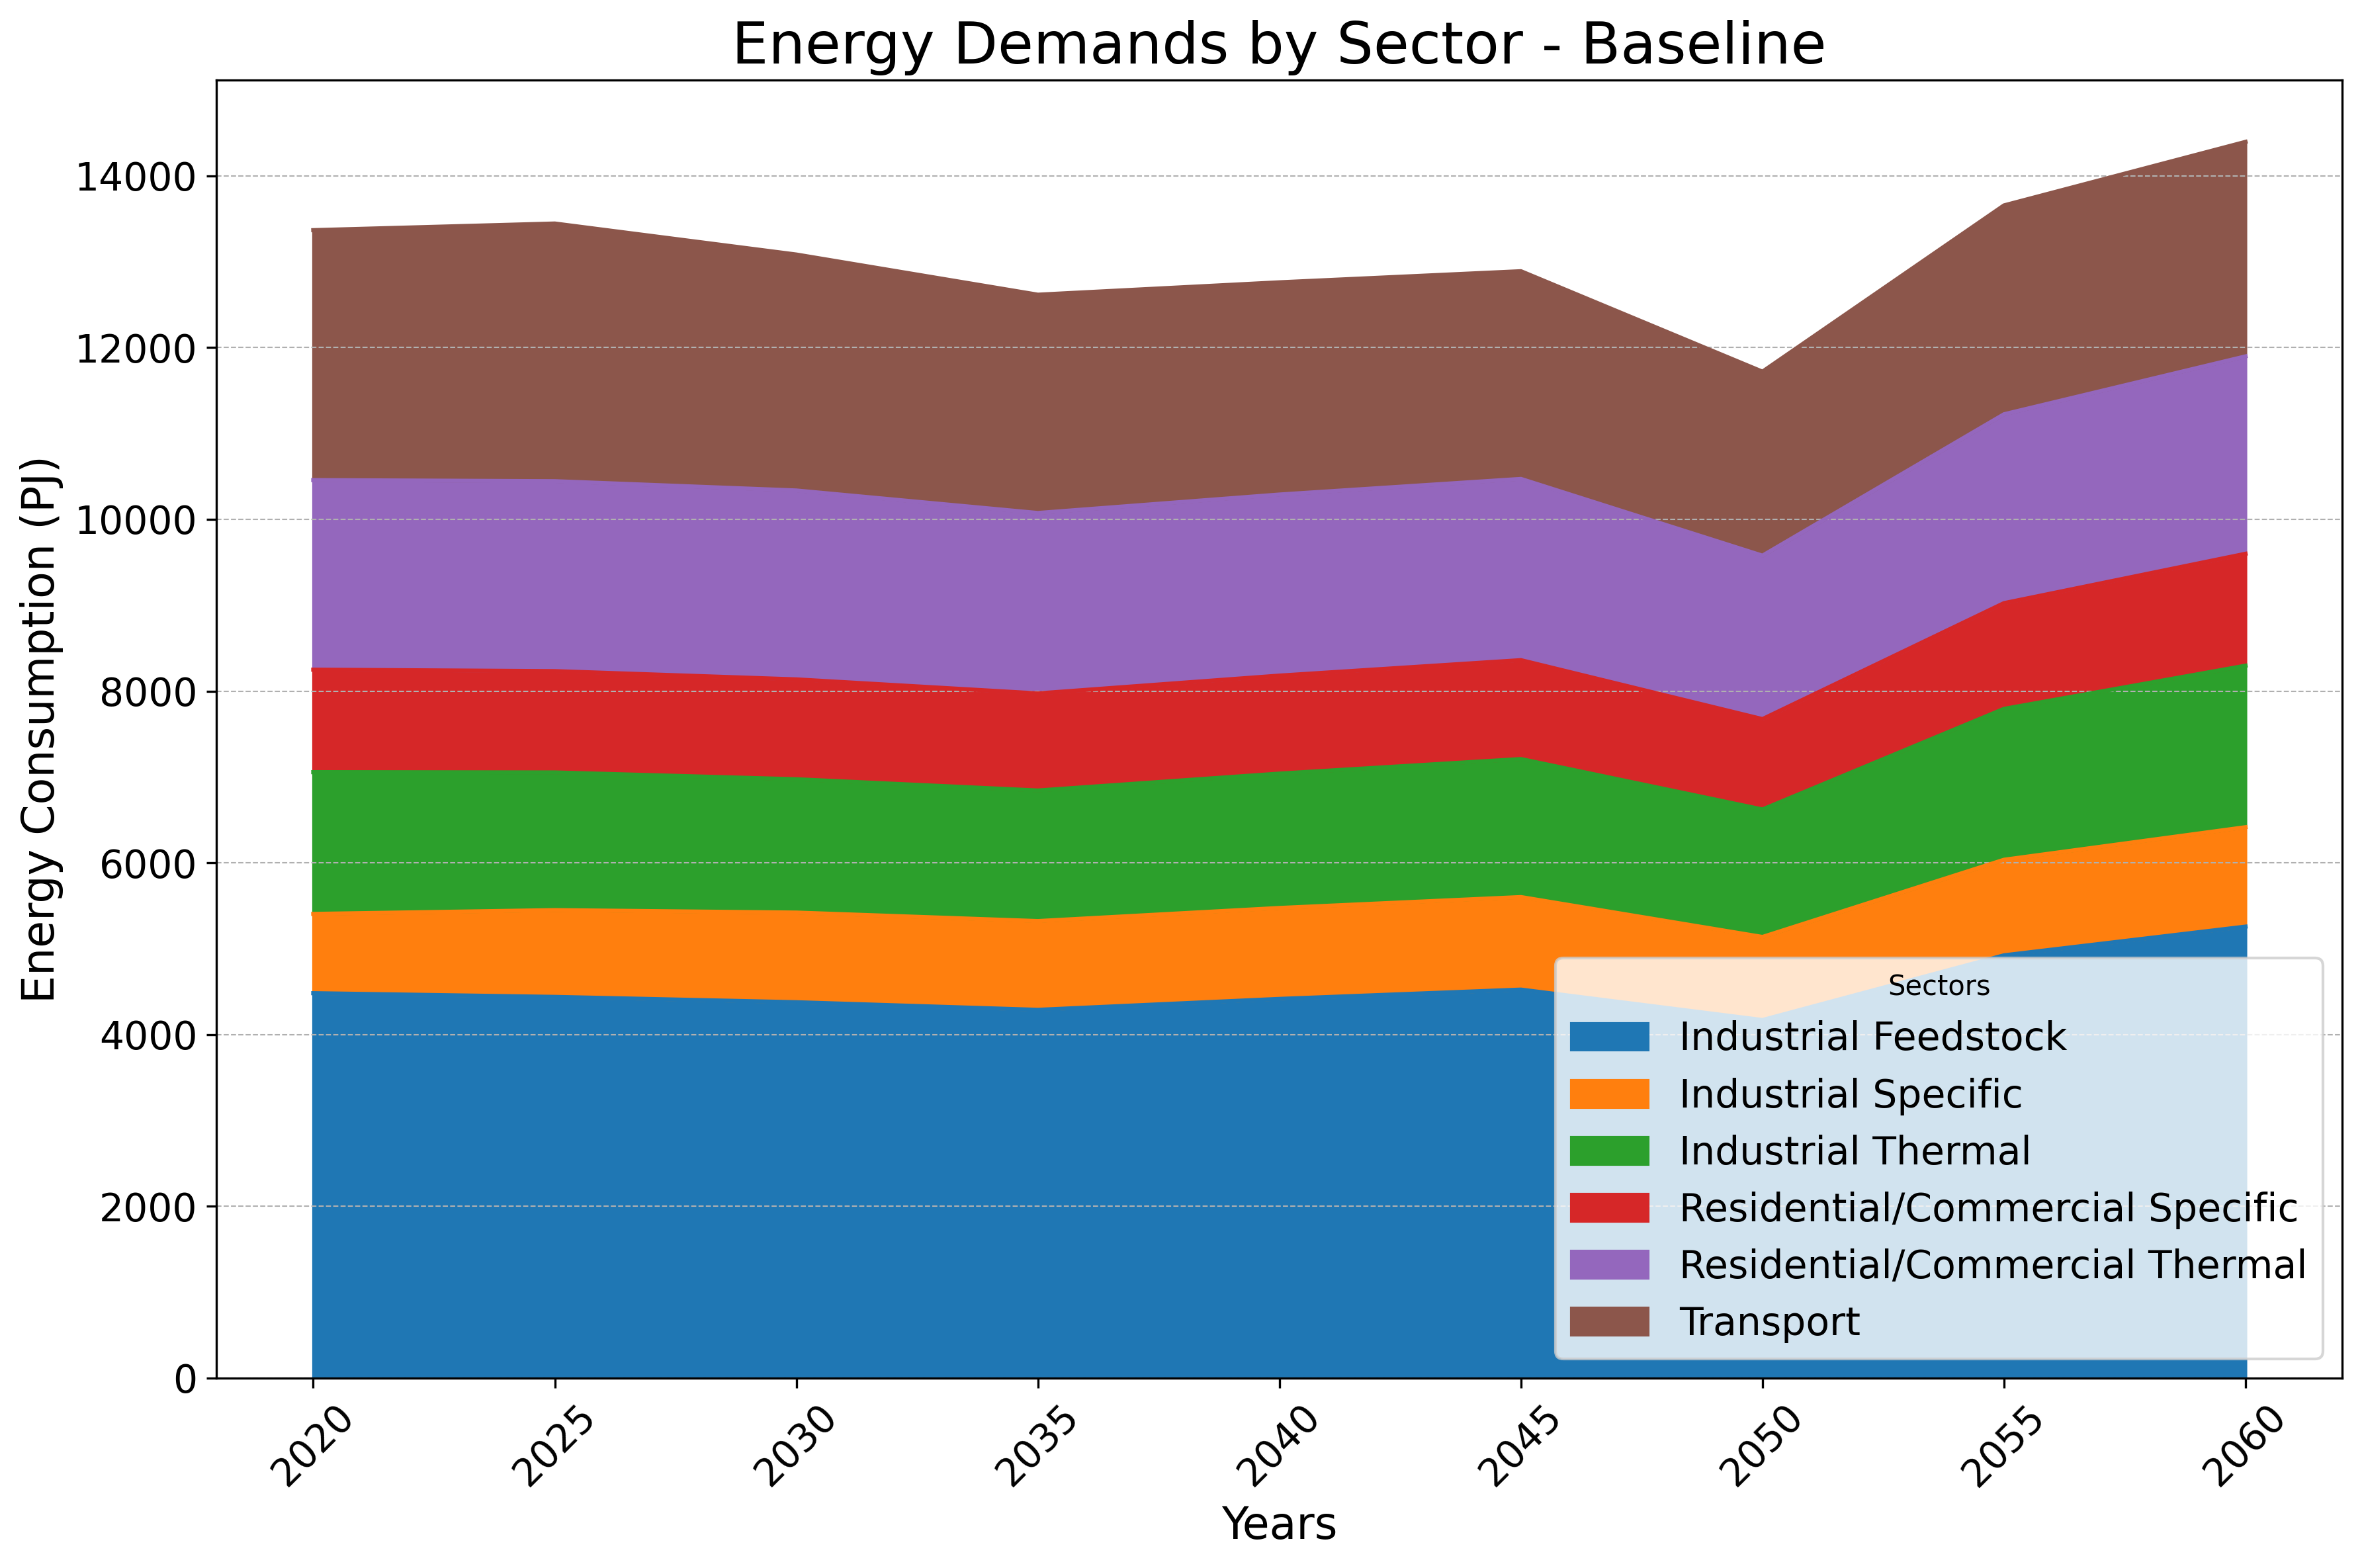

In [100]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the CSV file
file_path = 'demands_baseline.csv'
df = pd.read_csv(file_path)

# Sum the values for all nodes and convert GWh to PJ
df_grouped = df.groupby(['year', 'commodity'])['value'].sum().reset_index()
df_grouped['value'] = df_grouped['value'] * 35.36  # Convert GWh to PJ correctly

# Map for changing commodity labels
commodity_labels = {
    'i_spec': 'Industrial Specific',
    'i_therm': 'Industrial Thermal',
    'rc_spec': 'Residential/Commercial Specific',
    'rc_therm': 'Residential/Commercial Thermal',
    'i_feed': 'Industrial Feedstock',
    'transport':'Transport'
}

# Apply the new labels
df_grouped['commodity'] = df_grouped['commodity'].map(commodity_labels)

# Function to apply cumulative growth rate
def apply_cumulative_growth_rate(df, start_year, end_year, growth_rates):
    for year in range(start_year, end_year + 1):
        # Calculate the cumulative growth factor
        cumulative_growth_factor = np.prod([1 + rate for rate in growth_rates[:year - start_year]])
        # Apply the growth factor to the value
        df.loc[df['year'] == year, 'value'] *= cumulative_growth_factor
    return df

# Define the growth rates for each period (in decimal form)
growth_rates = [0.01, 0.0112]  # Example growth rates (1% and 1.12%)

# Generate growth rates for each year from 2035 to 2060
growth_rates_per_year = np.random.uniform(growth_rates[0], growth_rates[1], 2060 - 2035 + 1)

# Group by 'Commodity' and apply the cumulative growth rate function to each group
df_grouped = df_grouped.groupby('commodity').apply(lambda df: apply_cumulative_growth_rate(df, 2035, 2060, growth_rates_per_year))

# Reset the index to get back the original DataFrame structure
df_grouped = df_grouped.reset_index(drop=True)

# Create a pivot table for plotting
df_pivot = df_grouped.pivot(index='year', columns='commodity', values='value')

# Plotting
fig, ax = plt.subplots(figsize=(12, 8), dpi=300)
df_pivot.plot(kind='area', stacked=True, ax=ax)

# Add titles and labels with increased fontsize
plt.title('Energy Demands by Sector - Baseline', fontsize=21)
plt.xlabel('Years', fontsize=16)
plt.ylabel('Energy Consumption (PJ)', fontsize=16)

# Increase the size of tick labels
plt.xticks(rotation=45, fontsize=14)
plt.yticks(fontsize=14)

# Add a legend
plt.legend(title='Sectors', fontsize=14)

# Add a grid
plt.grid(True, axis='y', linestyle='--', linewidth=0.5)

# Display the plot
plt.tight_layout()
plt.show()


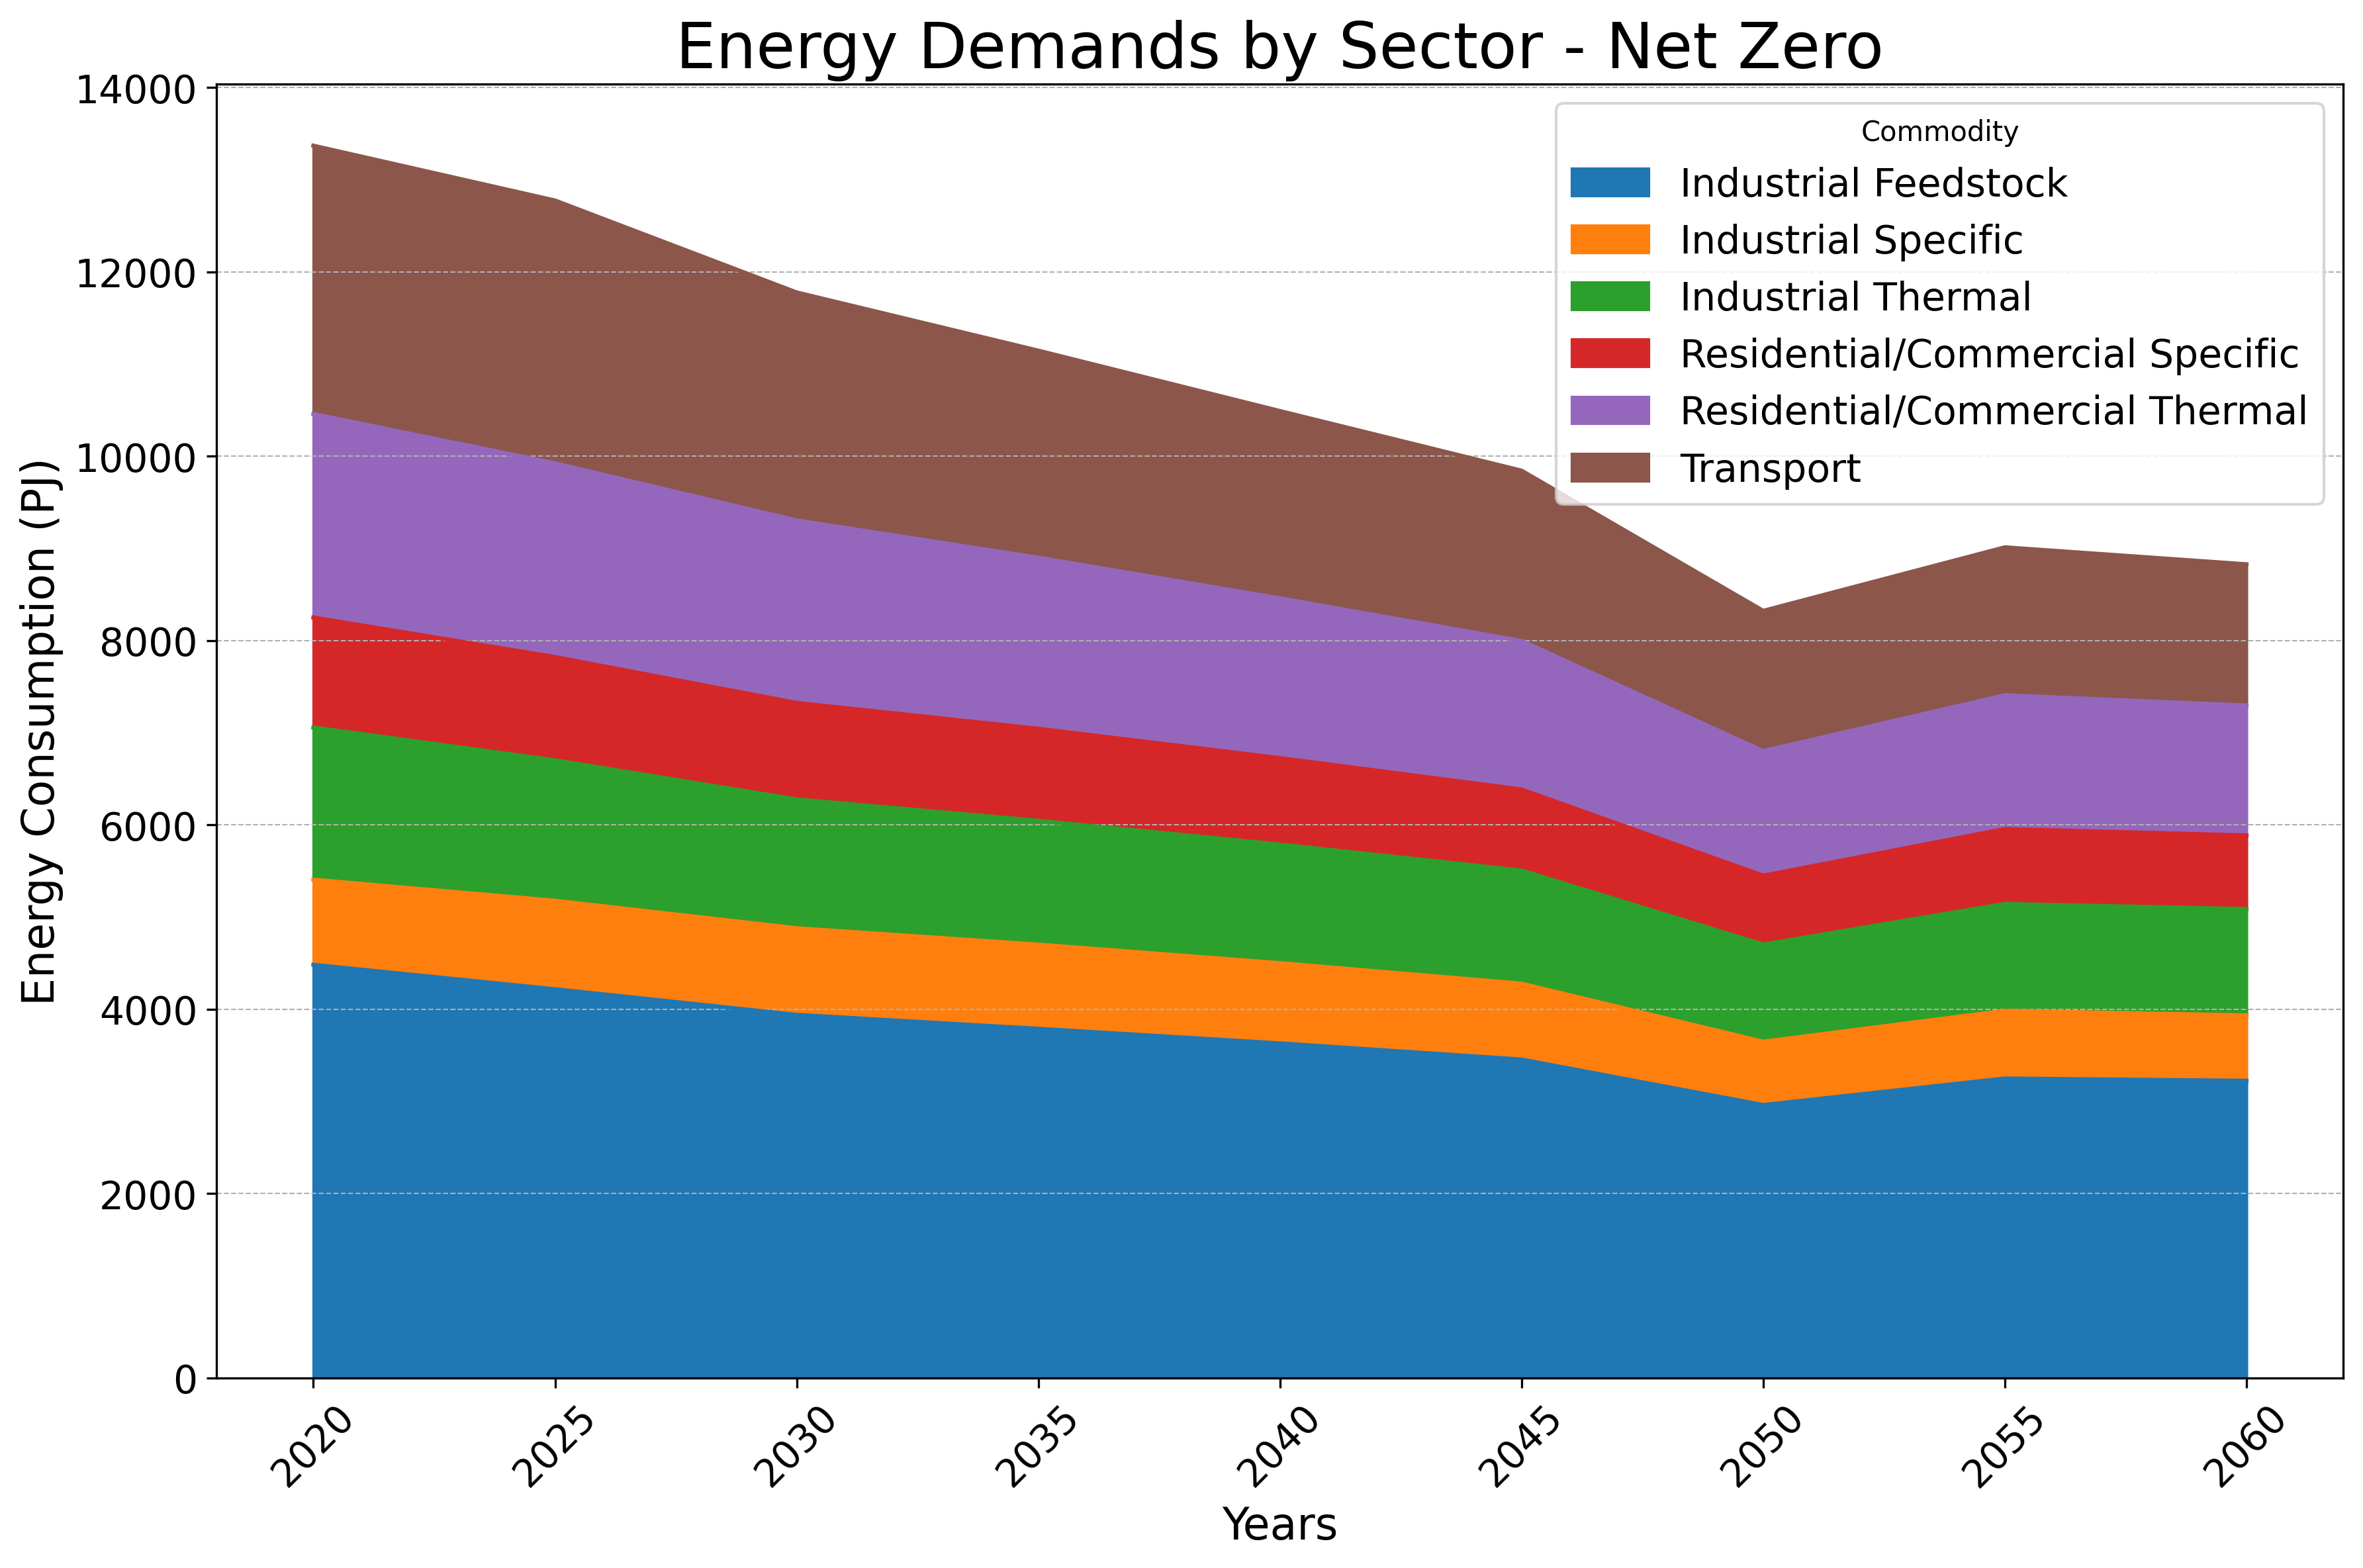

In [108]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the CSV file
file_path = 'demands_baseline.csv'
df = pd.read_csv(file_path)

# Sum the values for all nodes and convert GWh to PJ
df_grouped = df.groupby(['year', 'commodity'])['value'].sum().reset_index()
df_grouped['value'] = df_grouped['value'] * 35.36  # Convert GWh to PJ

# Define the years and calculate reduction factors
years = np.array([2020, 2025, 2030, 2035, 2040, 2045, 2050, 2055, 2060])
reduction_factors = np.interp(years, [2020, 2030, 2060], [1.0, 0.9, 0.8])

# Apply reduction factors to the values in df_grouped
df_grouped['reduction_factor'] = df_grouped['year'].apply(lambda x: np.interp(x, years, reduction_factors))
df_grouped['reduced_value'] = df_grouped['value'] * df_grouped['reduction_factor']

# Map for changing commodity labels
commodity_labels = {
    'i_spec': 'Industrial Specific',
    'i_therm': 'Industrial Thermal',
    'rc_spec': 'Residential/Commercial Specific',
    'rc_therm': 'Residential/Commercial Thermal',
    'i_feed': 'Industrial Feedstock',
    'transport':'Transport'
}

# Apply the new labels
df_grouped['commodity'] = df_grouped['commodity'].map(commodity_labels)

# Pivot the dataframe to get commodities as columns and years as index for the reduced values
df_pivot_reduced = df_grouped.pivot(index='year', columns='commodity', values='reduced_value')

# Plotting the reduced values
fig, ax = plt.subplots(figsize=(12, 8), dpi=300)
df_pivot_reduced.plot(kind='area', stacked=True, ax=ax)

# Add titles and labels with increased fontsize
plt.title('Energy Demands by Sector - Net Zero', fontsize=23)
plt.xlabel('Years', fontsize=16)
plt.ylabel('Energy Consumption (PJ)', fontsize=16)

# Increase the size of tick labels
plt.xticks(rotation=45, fontsize=14)
plt.yticks(fontsize=14)

# Add a legend
plt.legend(title='Commodity', fontsize=14)

# Add a grid
plt.grid(True, axis='y', linestyle='--', linewidth=0.5)

# Display the plot
plt.tight_layout()
plt.show()


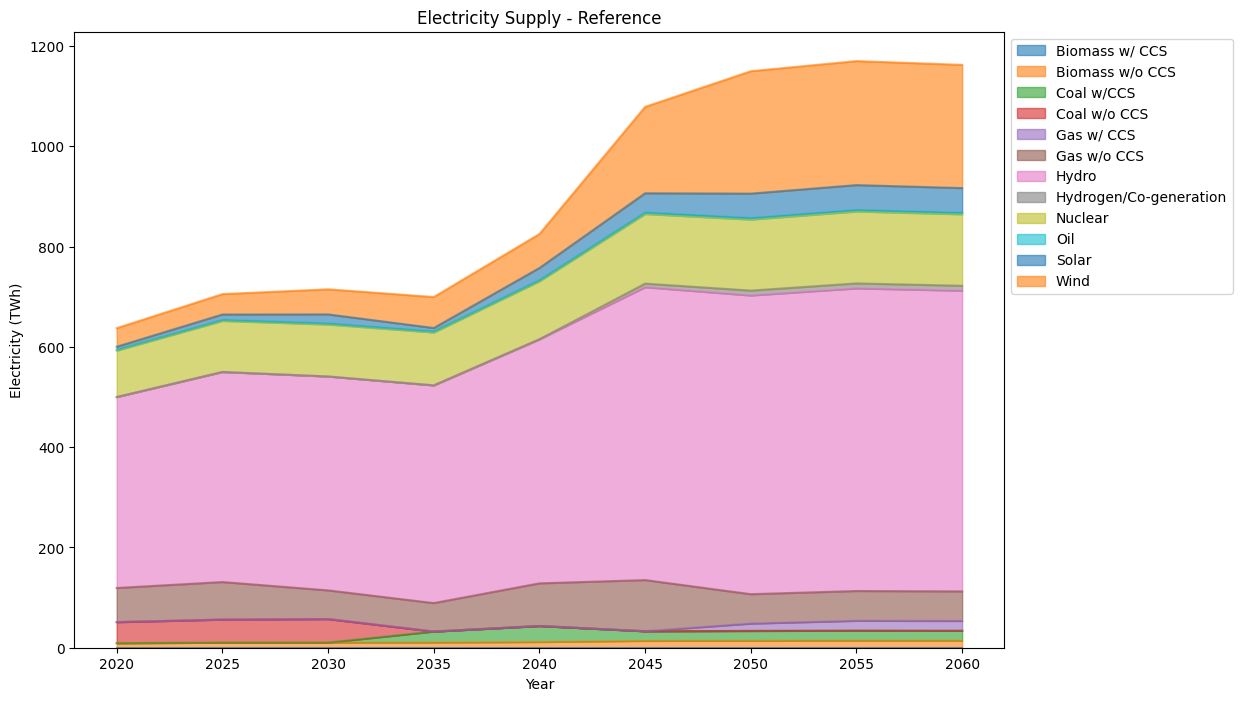

In [113]:
import matplotlib.pyplot as plt
import pandas as pd

# Updated data
data = {
    'Variable': [
        'Secondary Energy|Electricity|Biomass w/ CCS',
        'Secondary Energy|Electricity|Biomass w/o CCS',
        'Secondary Energy|Electricity|Coal w/CCS',
        'Secondary Energy|Electricity|Coal w/o CCS',
        'Secondary Energy|Electricity|Gas w/ CCS',
        'Secondary Energy|Electricity|Gas w/o CCS',
        'Secondary Energy|Electricity|Hydro',
        'Secondary Energy|Electricity|Hydrogen/Co-generation',
        'Secondary Energy|Electricity|Nuclear',
        'Secondary Energy|Electricity|Oil',
        'Secondary Energy|Electricity|Solar',
        'Secondary Energy|Electricity|Wind'
    ],
    '2020': [0, 9.141128178, 0, 41.91366599, 0, 68.03749929, 380.8973307, 0, 92.55926421, 2.04268721, 5.745057778, 37.02370568],
    '2025': [0, 10.055241, 0, 46.10503259, 0, 74.84124922, 418.9870638, 0, 101.8151906, 2.246955931, 10.53260593, 40.72607625],
    '2030': [0, 10.23806356, 0, 46.94330591, 0, 57.19524188, 426.6050104, 0, 103.6663759, 2.287809675, 17.87351309, 50.04583665],
    '2035': [0, 10.42088612, 21.83121956, 0, 0, 56.76117085, 434.222957, 0, 105.5175612, 2.328663419, 6.549365867, 61.85512208],
    '2040': [0, 11.42641022, 31.91698766, 0, 0, 85.04687411, 486.7340618, 0, 115.6990803, 2.553359013, 23.93774074, 67.82359877],
    '2045': [0, 13.71169227, 19.15019259, 0, 0, 102.0562489, 584.0808741, 7.181322223, 138.8388963, 3.064030815, 38.30038519, 172.3517333],
    '2050': [0, 13.98592611, 19.53319645, 0, 14.64989733, 58.59958934, 595.7624916, 9.766598223, 141.6156742, 3.125311431, 48.63765915, 244.1649556],
    '2055': [0, 14.16874868, 19.78853235, 0, 19.78853235, 59.36559704, 603.5502366, 9.894266174, 143.4668595, 3.166165176, 49.47133087, 247.3566543],
    '2060': [0, 14.07733739, 19.6608644, 0, 19.6608644, 58.98259319, 599.6563641, 9.830432198, 142.5412669, 3.145738304, 49.15216099, 245.760805]
}

# Convert to DataFrame
df_plot = pd.DataFrame(data)

# Extract labels
labels = [label.split('|')[-1] for label in df_plot['Variable']]
df_plot['Variable'] = labels

# Set the index to 'Variable'
df_plot.set_index('Variable', inplace=True)

# Convert the data to numeric for plotting
df_plot = df_plot.apply(pd.to_numeric)

# Plotting
df_plot.T.plot(kind='area', stacked=True, figsize=(12, 8), alpha=0.6)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.xlabel('Year')
plt.ylabel('Electricity (TWh)')
plt.title('Electricity Supply - Reference')
plt.show()


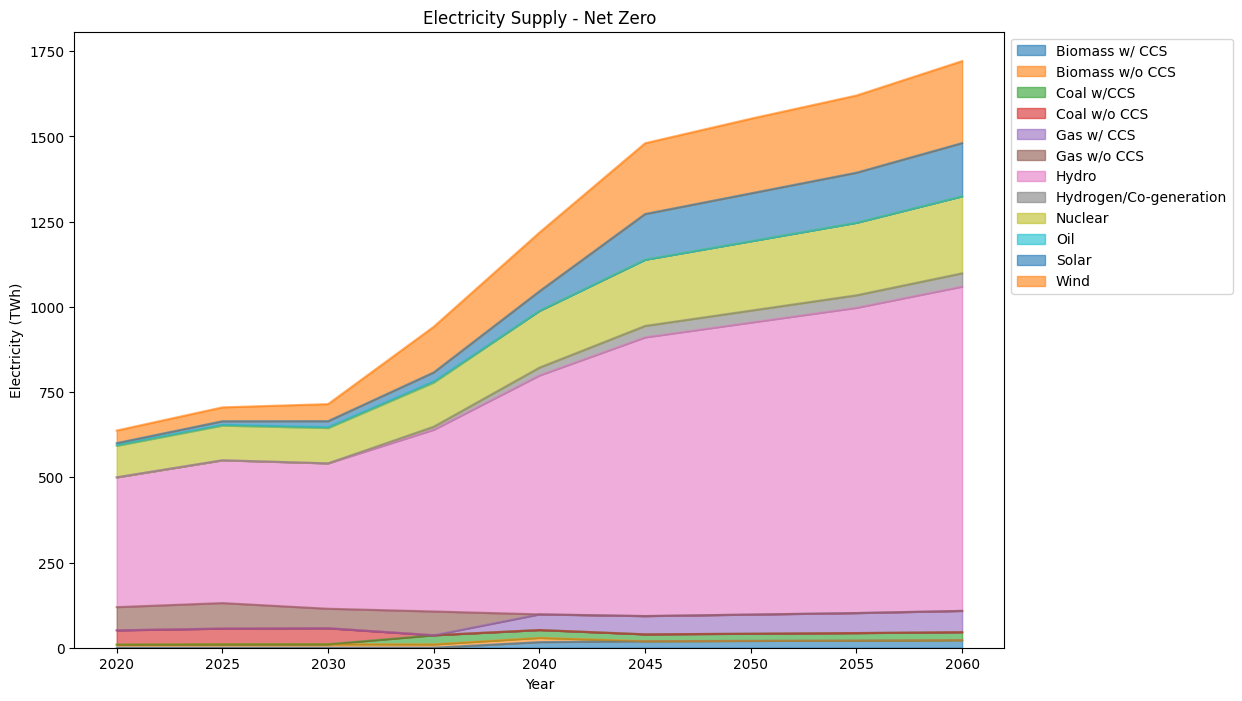

In [114]:
import matplotlib.pyplot as plt
import pandas as pd

# Updated data for Net Zero
data_net_zero = {
    'Variable': [
        'Secondary Energy|Electricity|Biomass w/ CCS',
        'Secondary Energy|Electricity|Biomass w/o CCS',
        'Secondary Energy|Electricity|Coal w/CCS',
        'Secondary Energy|Electricity|Coal w/o CCS',
        'Secondary Energy|Electricity|Gas w/ CCS',
        'Secondary Energy|Electricity|Gas w/o CCS',
        'Secondary Energy|Electricity|Hydro',
        'Secondary Energy|Electricity|Hydrogen/Co-generation',
        'Secondary Energy|Electricity|Nuclear',
        'Secondary Energy|Electricity|Oil',
        'Secondary Energy|Electricity|Solar',
        'Secondary Energy|Electricity|Wind'
    ],
    '2020': [0, 9.141128178, 0, 41.91366599, 0, 68.03749929, 380.8973307, 0, 92.55926421, 2.04268721, 5.745057778, 37.02370568],
    '2025': [0, 10.055241, 0, 46.10503259, 0, 74.84124922, 418.9870638, 0, 101.8151906, 2.246955931, 10.53260593, 40.72607625],
    '2030': [0, 10.23806356, 0, 46.94330591, 0, 57.19524188, 426.6050104, 0, 103.6663759, 2.287809675, 17.87351309, 50.04583665],
    '2035': [0, 9.830432198, 26.81026963, 0, 0, 69.70670104, 533.256263, 8.936756544, 129.5829699, 2.859762094, 26.81026963, 134.0513482],
    '2040': [16.45403072, 12.52422596, 22.98023111, 0, 45.96046223, 0, 700.897049, 22.98023111, 166.6066756, 0, 57.45057778, 172.3517333],
    '2045': [19.19636917, 0, 20.10770222, 0, 53.62053926, 0, 817.7132238, 33.51283704, 194.3744548, 0, 134.0513482, 207.7795896],
    '2050': [20.11048199, 0, 21.06521185, 0, 56.17389828, 0, 856.6519487, 35.10868642, 203.6303813, 0, 140.4347457, 219.0782033],
    '2055': [21.02459481, 0, 22.02272148, 0, 58.72725729, 0, 895.5906737, 36.70453581, 212.8863077, 0, 146.8181432, 226.540395],
    '2060': [22.33538458, 0, 23.39574, 0, 62.38864, 0, 951.42676, 38.9929, 226.15882, 0, 155.9716, 240.6641788]
}

# Convert to DataFrame
df_plot_net_zero = pd.DataFrame(data_net_zero)

# Extract labels
labels_net_zero = [label.split('|')[-1] for label in df_plot_net_zero['Variable']]
df_plot_net_zero['Variable'] = labels_net_zero

# Set the index to 'Variable'
df_plot_net_zero.set_index('Variable', inplace=True)

# Convert the data to numeric for plotting
df_plot_net_zero = df_plot_net_zero.apply(pd.to_numeric)

# Plotting
df_plot_net_zero.T.plot(kind='area', stacked=True, figsize=(12, 8), alpha=0.6)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.xlabel('Year')
plt.ylabel('Electricity (TWh)')
plt.title('Electricity Supply - Net Zero')
plt.show()


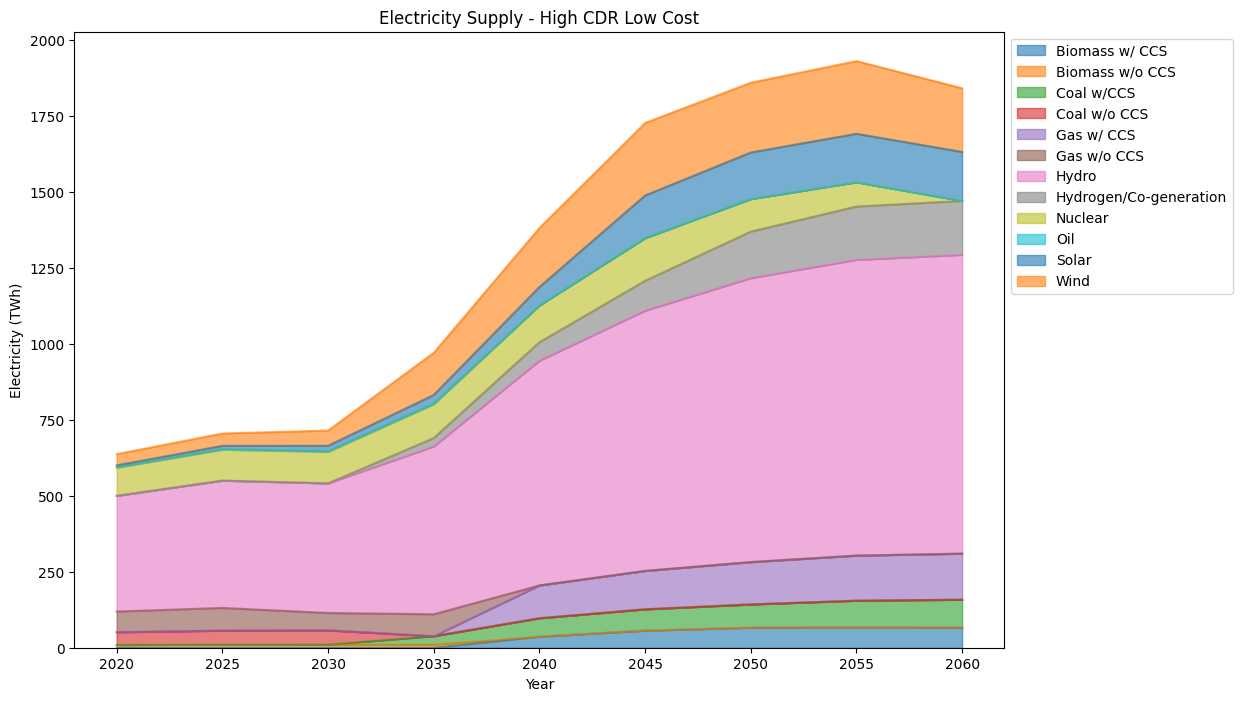

In [115]:
import matplotlib.pyplot as plt
import pandas as pd

# Updated data for High CDR Low Cost
data_high_cdr_low_cost = {
    'Variable': [
        'Secondary Energy|Electricity|Biomass w/ CCS',
        'Secondary Energy|Electricity|Biomass w/o CCS',
        'Secondary Energy|Electricity|Coal w/CCS',
        'Secondary Energy|Electricity|Coal w/o CCS',
        'Secondary Energy|Electricity|Gas w/ CCS',
        'Secondary Energy|Electricity|Gas w/o CCS',
        'Secondary Energy|Electricity|Hydro',
        'Secondary Energy|Electricity|Hydrogen/Co-generation',
        'Secondary Energy|Electricity|Nuclear',
        'Secondary Energy|Electricity|Oil',
        'Secondary Energy|Electricity|Solar',
        'Secondary Energy|Electricity|Wind'
    ],
    '2020': [0, 9.141128178, 0, 41.91366599, 0, 68.03749929, 380.8973307, 0, 92.55926421, 2.04268721, 5.745057778, 37.02370568],
    '2025': [0, 10.055241, 0, 46.10503259, 0, 74.84124922, 418.9870638, 0, 101.8151906, 2.246955931, 10.53260593, 40.72607625],
    '2030': [0, 10.23806356, 0, 46.94330591, 0, 57.19524188, 426.6050104, 0, 103.6663759, 2.287809675, 17.87351309, 50.04583665],
    '2035': [0, 10.18151906, 27.76777926, 0, 0, 72.19622608, 552.3011295, 27.76777926, 111.071117, 2.961896455, 27.76777926, 138.8388963],
    '2040': [36.38536593, 0, 60.64227655, 0, 107.9432523, 0, 739.8357739, 60.64227655, 121.2845531, 0, 60.64227655, 194.055285],
    '2045': [56.17389828, 0, 70.21737285, 0, 126.3912711, 0, 856.6519487, 98.30432198, 140.4347457, 0, 140.4347457, 238.7390677],
    '2050': [65.87666252, 0, 76.60077038, 0, 139.4134021, 0, 934.5293986, 153.2015408, 107.2410785, 0, 153.2015408, 229.8023111],
    '2055': [67.02567408, 0, 87.77171606, 0, 148.4139926, 0, 973.4681235, 175.5434321, 79.79246914, 0, 159.5849383, 239.3774074],
    '2060': [66.11414, 0, 91.91478, 0, 151.57876, 0, 983.6494, 177.3794, 0, 0, 161.254, 209.6302]
}

# Convert to DataFrame
df_plot_high_cdr_low_cost = pd.DataFrame(data_high_cdr_low_cost)

# Extract labels
labels_high_cdr_low_cost = [label.split('|')[-1] for label in df_plot_high_cdr_low_cost['Variable']]
df_plot_high_cdr_low_cost['Variable'] = labels_high_cdr_low_cost

# Set the index to 'Variable'
df_plot_high_cdr_low_cost.set_index('Variable', inplace=True)

# Convert the data to numeric for plotting
df_plot_high_cdr_low_cost = df_plot_high_cdr_low_cost.apply(pd.to_numeric)

# Plotting
df_plot_high_cdr_low_cost.T.plot(kind='area', stacked=True, figsize=(12, 8), alpha=0.6)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.xlabel('Year')
plt.ylabel('Electricity (TWh)')
plt.title('Electricity Supply - High CDR Low Cost')
plt.show()


matplotlib.category - INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
matplotlib.category - INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
matplotlib.category - INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
matplotlib.category - INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
matplotlib.category - INFO: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these

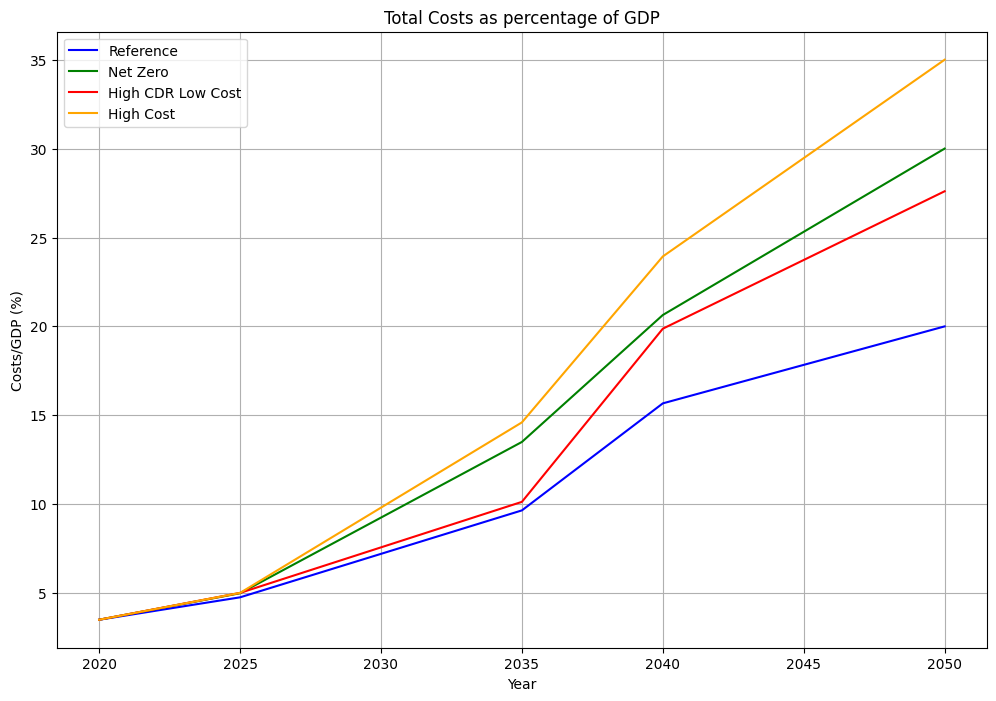

In [116]:
import matplotlib.pyplot as plt
import pandas as pd

# Data for GDP Relative Change (%) vs Base year (2020)
data_gdp = {
    'Scenario': ['Reference', 'Net Zero', 'High CDR Low Cost', 'High Cost'],
    '2020': [3.50, 3.50, 3.50, 3.50],
    '2025': [4.76, 4.99, 5.01, 5.01],
    '2030': [7.205, 9.245, 7.57, 9.805],
    '2035': [9.65, 13.5, 10.13, 14.6],
    '2040': [15.67, 20.64, 19.87, 23.934],
    '2045': [17.835, 25.32, 23.735, 29.467],
    '2050': [20, 30, 27.6, 35]
}

# Convert to DataFrame
df_gdp = pd.DataFrame(data_gdp)

# Set the index to 'Scenario'
df_gdp.set_index('Scenario', inplace=True)

# Plotting
plt.figure(figsize=(12, 8))

for scenario in df_gdp.index:
    plt.plot(df_gdp.columns, df_gdp.loc[scenario], label=scenario)

# Set colors for each scenario
colors = ['blue', 'green', 'red', 'orange']
for i, line in enumerate(plt.gca().get_lines()):
    line.set_color(colors[i])

plt.legend(loc='upper left')
plt.xlabel('Year')
plt.ylabel('Costs/GDP (%)')
plt.title('Total Costs as percentage of GDP')
plt.grid(True)
plt.show()


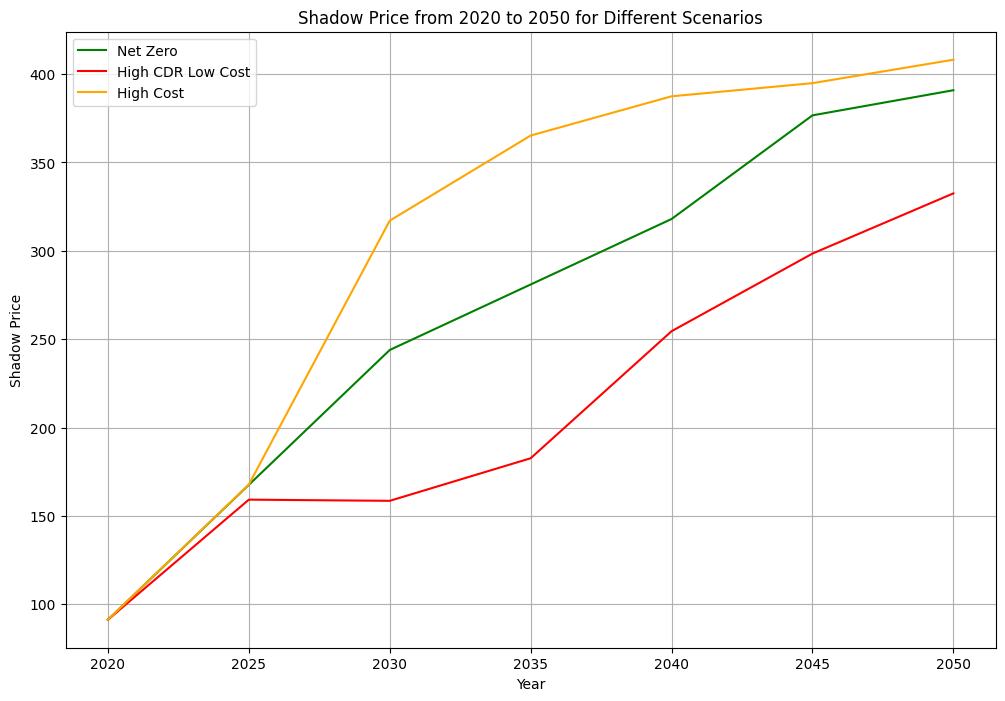

In [120]:
import matplotlib.pyplot as plt
import pandas as pd

# Data for Shadow Prices from 2020 to 2050 for three scenarios
data_shadow_price = {
    'Year': [2020, 2025, 2030, 2035, 2040, 2045, 2050],
    'Net Zero': [91.25, 167.57, 243.89, 280.945, 318, 376.65, 390.87],
    'High CDR Low Cost': [91.25, 159.1915, 158.5285, 182.61425, 254.5, 298.43, 332.5],
    'High Cost': [91.25, 167.73757, 317.057, 365.2285, 387.43, 394.87, 408.131]
}

# Convert to DataFrame
df_shadow_price = pd.DataFrame(data_shadow_price)

# Plotting
plt.figure(figsize=(12, 8))

for scenario in df_shadow_price.columns[1:]:
    plt.plot(df_shadow_price['Year'], df_shadow_price[scenario], label=scenario)

# Set colors for each scenario
colors = ['green', 'red', 'orange']
for i, line in enumerate(plt.gca().get_lines()):
    line.set_color(colors[i])

plt.legend(loc='upper left')
plt.xlabel('Year')
plt.ylabel('Shadow Price')
plt.title('Shadow Price from 2020 to 2050 for Different Scenarios')
plt.grid(True)
plt.show()
